# Hito 2: modelo DH del ABB IRB 120, Pieper, LSPB, Jacobiano, singularidades y dinámica 1R

**IMT-342 Robótica · UCB Tarija**

Este es el punto de partida del pipeline de la guía oficial:

$$
T_d \xrightarrow{\text{Pieper}} q_f \xrightarrow{\text{LSPB}} q(t),\dot q(t),\ddot q(t) \xrightarrow{J(q)} \dot x
\xrightarrow{\text{rank }J} \text{singularidades} \xrightarrow{\text{1R}} \tau(t)
$$

En este paso se fijan las tres entradas de todo lo demás:

1. El **modelo geométrico** del robot (tabla DH y cinemática directa al TCP).
2. La **configuración inicial** $q_i$, desde donde arranca el movimiento.
3. La **pose objetivo** $T_d$, de la que sale $q_f$.

Después (secciones 2 y 3) se resuelve la **cinemática inversa analítica por Pieper**: las 8 ramas candidatas de cada
$T_d$, y su **verificación por cinemática directa** $T(q^{(k)}) \approx T_d$.

**Convenciones.** Longitudes en m, ángulos en rad (en grados solo al mostrarlos). Marco base con $z$ hacia arriba.
El TCP está sobre el eje $z_6$ de la brida, a 0.150 m de ella.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

import irb120_modelo as m
import pieper as pp
import seleccion_ramas as sel
import lspb
import jacobiano as jb

np.set_printoptions(precision=4, suppress=True)
FIG = Path("figuras"); FIG.mkdir(exist_ok=True)
VERIFICACIONES = []

def verificar(nombre, ok):
    VERIFICACIONES.append((nombre, bool(ok)))
    print(("✔ " if ok else "✘ ") + nombre)
    assert ok, nombre

## 1.1 Tabla Denavit-Hartenberg

Se usa la convención **DH clásica**. La transformada del marco $i-1$ al $i$ es

$$
A_i = R_z(\theta_i)\,T_z(d_i)\,T_x(a_i)\,R_x(\alpha_i) =
\begin{bmatrix}
\cos\theta_i & -\sin\theta_i\cos\alpha_i & \sin\theta_i\sin\alpha_i & a_i\cos\theta_i\\
\sin\theta_i & \cos\theta_i\cos\alpha_i & -\cos\theta_i\sin\alpha_i & a_i\sin\theta_i\\
0 & \sin\alpha_i & \cos\alpha_i & d_i\\
0&0&0&1
\end{bmatrix},
\qquad \theta_i = q_i + \text{offset}_i
$$

Los parámetros son de Bahani et al. (2023), Tabla I. Los offsets de las filas 2 y 6 hacen que el ángulo articular
$q$ coincida con el ángulo que muestra el controlador ABB: con $q = 0$ el brazo queda vertical y el antebrazo
horizontal, que es la posición de calibración.

In [ ]:
print(f"{'i':>2} {'d [m]':>7} {'a [m]':>7} {'alpha [deg]':>12} {'offset [deg]':>13} {'q_min [deg]':>12} {'q_max [deg]':>12} {'vmax [deg/s]':>13}")
for i, ((d, a, alpha, off), (lo, hi), v) in enumerate(zip(m.DH, m.LIMITES_DEG, m.VMAX_DEG_S), start=1):
    print(f"{i:>2} {d:7.3f} {a:7.3f} {np.rad2deg(alpha):12.1f} {np.rad2deg(off):13.1f} {lo:12.0f} {hi:12.0f} {v:13.0f}")
print(f"\nTCP: {m.TCP_M:.3f} m sobre z6 desde la brida")

 i   d [m]   a [m]  alpha [deg]  offset [deg]  q_min [deg]  q_max [deg]  vmax [deg/s]
 1   0.290   0.000        -90.0           0.0         -165          165           250
 2   0.000   0.270          0.0         -90.0         -110          110           250
 3   0.000   0.070        -90.0           0.0         -110           70           250
 4   0.302   0.000         90.0           0.0         -160          160           320
 5   0.000   0.000        -90.0           0.0         -120          120           320
 6   0.072   0.000          0.0         180.0         -400          400           420

TCP: 0.150 m sobre z6 desde la brida


## 1.2 Cinemática directa

La pose de la brida es el producto de las seis matrices, y el TCP se obtiene con una traslación fija sobre $z_6$:

$$
T_0^6(q) = A_1 A_2 A_3 A_4 A_5 A_6, \qquad T_0^{TCP}(q) = T_0^6(q)\,T_z(0.150)
$$

La matriz resultante contiene la orientación $R$ (columnas = ejes $x, y, z$ de la herramienta en el marco base) y la
posición $p$ del TCP:

$$
T_0^{TCP} = \begin{bmatrix} R & p \\ 0 & 1 \end{bmatrix}
$$

**Validación con el datasheet.** En la posición de calibración ($q = 0$) el datasheet de ABB da la brida en
$(0.374,\ 0,\ 0.630)$ m: $0.302 + 0.072 = 0.374$ m de alcance horizontal y $0.290 + 0.270 + 0.070 = 0.630$ m de
altura. El TCP debe quedar 0.150 m más adelante, en $x = 0.524$ m.

In [ ]:
F0 = m.marcos(m.Q_I)
p_brida, p_tcp = F0[6][:3, 3], F0[7][:3, 3]
print("Brida (tool0) en q = 0:", p_brida, "m")
print("TCP en q = 0:          ", p_tcp, "m")
verificar("la brida en q = 0 coincide con el datasheet (0.374, 0, 0.630) m", np.allclose(p_brida, [0.374, 0, 0.630], atol=1e-12))
verificar("el TCP en q = 0 está 0.150 m delante de la brida", np.allclose(p_tcp, [0.524, 0, 0.630], atol=1e-12))
verificar("la rotación de T(q = 0) es ortonormal con det = +1", m.es_rotacion(F0[7][:3, :3]))

# Prueba geométrica independiente: con q1 = 90 deg todo el brazo gira alrededor de z0,
# así que la brida debe pasar de (0.374, 0, 0.630) a (0, 0.374, 0.630).
q_prueba = np.deg2rad([90, 0, 0, 0, 0, 0])
verificar("con q1 = 90° la brida pasa a (0, 0.374, 0.630) m", np.allclose(m.marcos(q_prueba)[6][:3, 3], [0, 0.374, 0.630], atol=1e-12))

Brida (tool0) en q = 0: [0.374 0.    0.63 ] m
TCP en q = 0:           [0.524 0.    0.63 ] m
✔ la brida en q = 0 coincide con el datasheet (0.374, 0, 0.630) m
✔ el TCP en q = 0 está 0.150 m delante de la brida
✔ la rotación de T(q = 0) es ortonormal con det = +1
✔ con q1 = 90° la brida pasa a (0, 0.374, 0.630) m


## 1.3 Configuración inicial $q_i$

Se toma $q_i = (0, 0, 0, 0, 0, 0)$, la **posición de calibración de ABB**. Es la única postura de referencia que
define el fabricante (se usa con `MoveAbsJ` para actualizar los contadores de revolución), así que no hay que
inventarla.

**Observación para los pasos siguientes:** en $q_i$ se cumple $q_5 = 0$, por lo que los ejes 4 y 6 quedan
alineados. Además el centro de muñeca (origen de los marcos 4 y 5) está en $(0.302,\ 0,\ 0.630)$ m. Es una singularidad de muñeca conocida que se analizará en el paso del Jacobiano; no impide mover el robot
en espacio articular.

In [ ]:
print("q_i [deg] =", np.rad2deg(m.Q_I))
verificar("q_i está dentro de los límites articulares", m.dentro_de_limites(m.Q_I))
print("\nOrígenes de los marcos en q_i [m]:")
nombres = ["0 base", "1 hombro", "2 codo", "3", "4 muñeca", "5 muñeca", "6 brida", "TCP"]
for nombre, T in zip(nombres, F0):
    print(f"  {nombre:<9} {T[:3, 3]}")
T_i = F0[-1]
print("\nPose inicial del TCP  T_i = T_0^TCP(q_i):\n", T_i)
print("Eje de la herramienta z_TCP =", T_i[:3, 2], "(apunta hacia +x, horizontal)")
print("En q_i el pitch vale 90°: roll y yaw no son únicos (bloqueo de cardán), por eso la orientación")
print("se describe con los ejes de R y no con roll-pitch-yaw.")

q_i [deg] = [0. 0. 0. 0. 0. 0.]
✔ q_i está dentro de los límites articulares

Orígenes de los marcos en q_i [m]:
  0 base    [0. 0. 0.]
  1 hombro  [0.   0.   0.29]
  2 codo    [ 0.   -0.    0.56]
  3         [ 0.   -0.    0.63]
  4 muñeca  [ 0.302 -0.     0.63 ]
  5 muñeca  [ 0.302 -0.     0.63 ]
  6 brida   [0.374 0.    0.63 ]
  TCP       [0.524 0.    0.63 ]

Pose inicial del TCP  T_i = T_0^TCP(q_i):
 [[-0.    -0.     1.     0.524]
 [-0.     1.     0.     0.   ]
 [-1.    -0.    -0.     0.63 ]
 [ 0.     0.     0.     1.   ]]
Eje de la herramienta z_TCP = [ 1.  0. -0.] (apunta hacia +x, horizontal)
En q_i el pitch vale 90°: roll y yaw no son únicos (bloqueo de cardán), por eso la orientación
se describe con los ejes de R y no con roll-pitch-yaw.


## 1.4 Pose objetivo $T_d$

Hay **una sola pose objetivo**: el TCP en $p_d = (0.25,\,-0.10,\,0.12)$ m con la herramienta apuntando a la mesa
($-Z_0$). Se escribe como posición más roll-pitch-yaw del TCP en el marco base:

$$
T_d = \begin{bmatrix} R_d & p_d \\ 0 & 1\end{bmatrix},\qquad
R_d = R_z(\text{yaw})\,R_y(\text{pitch})\,R_x(\text{roll})
$$

De esta $T_d$ se obtiene $q_f$ con la cinemática inversa analítica (Pieper); la validación FK, la selección de rama y
el LSPB usan esa misma pose. La pose está en `POSES_OBJETIVO` de `irb120_modelo.py`: si el docente entrega otra, se
cambia ahí y todo el notebook se recalcula con ella.

In [ ]:
T_D = {nombre: m.pose_xyz_rpy(*pose) for nombre, pose in m.POSES_OBJETIVO.items()}
for nombre, T in T_D.items():
    x, y, z, roll, pitch, yaw = m.POSES_OBJETIVO[nombre]
    print(f"{nombre}:  p_d = ({x}, {y}, {z}) m,  roll = {roll}°, pitch = {pitch}°, yaw = {yaw}°")
    print(T)
    print("  eje de la herramienta z_d =", T[:3, 2])
    verificar(f"{nombre}: R_d es una rotación válida (ortonormal, det = +1)", m.es_rotacion(T[:3, :3]))
    print()

T_d:  p_d = (0.25, -0.1, 0.12) m,  roll = 180.0°, pitch = 0.0°, yaw = 0.0°
[[ 1.    0.    0.    0.25]
 [ 0.   -1.   -0.   -0.1 ]
 [ 0.    0.   -1.    0.12]
 [ 0.    0.    0.    1.  ]]
  eje de la herramienta z_d = [ 0. -0. -1.]
✔ T_d: R_d es una rotación válida (ortonormal, det = +1)



## 1.5 Vista del punto de partida

El robot en $q_i$ (eslabones entre los orígenes de los marcos DH) y la pose objetivo con sus ejes
($x$ rojo, $y$ verde, $z$ azul).

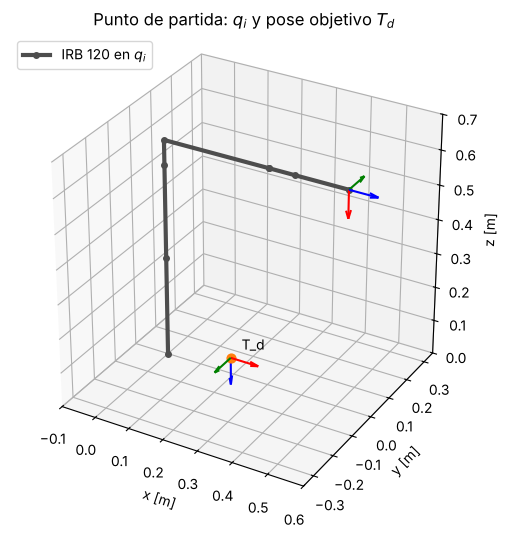

In [ ]:
def ejes(ax, T, largo=0.08):
    for k, color in enumerate("rgb"):
        ax.quiver(*T[:3, 3], *(largo * T[:3, k]), color=color, linewidth=1.5)

fig = plt.figure(figsize=(6.5, 5.5))
ax = fig.add_subplot(projection="3d")
P = np.array([T[:3, 3] for T in F0])
ax.plot(P[:, 0], P[:, 1], P[:, 2], "-o", color="0.3", linewidth=3, markersize=4, label="IRB 120 en $q_i$")
ejes(ax, F0[-1])
for nombre, T in T_D.items():
    ax.scatter(*T[:3, 3], color="tab:orange", s=40)
    ax.text(*(T[:3, 3] + 0.02), nombre)
    ejes(ax, T)
ax.set_xlabel("x [m]"); ax.set_ylabel("y [m]"); ax.set_zlabel("z [m]")
ax.set_xlim(-0.1, 0.6); ax.set_ylim(-0.35, 0.35); ax.set_zlim(0, 0.7)
ax.set_box_aspect((0.7, 0.7, 0.7)); ax.legend(loc="upper left")
ax.set_title("Punto de partida: $q_i$ y pose objetivo $T_d$")
fig.tight_layout(); fig.savefig(FIG / "P1_punto_de_partida.png", dpi=150); fig.savefig(FIG / "P1_punto_de_partida.pdf")
plt.show()

## 2. Cinemática inversa analítica (método de Pieper)

### 2.1 Por qué existe solución cerrada: desacoplamiento

El teorema de Pieper garantiza solución cerrada para un 6R cuando **tres ejes consecutivos se cortan en un punto**.
En el IRB 120 los ejes 4, 5 y 6 se cortan en el **centro de muñeca** $W$ ($a_4 = a_5 = d_5 = 0$ en la tabla DH).
Eso separa el problema en dos:

- **Posición:** $W$ depende solo de $q_1, q_2, q_3$ (el brazo).
- **Orientación:** con el brazo resuelto, $q_4, q_5, q_6$ (la muñeca) completan $R_d$.

$W$ se obtiene retrocediendo desde el TCP a lo largo del eje de la herramienta $z_d$ (tercera columna de $R_d$) la
distancia muñeca-brida más la herramienta:

$$
p_W = p_d - (d_6 + d_{TCP})\,z_d = p_d - (0.072 + 0.150)\,z_d
$$

$W$ solo es alcanzable si su distancia al hombro $S = (0, 0, d_1)$ cumple
$|L_2 - L_3| \le \|W - S\| \le L_2 + L_3$, con $L_2 = a_2 = 0.270$ m y $L_3 = \sqrt{d_4^2 + a_3^2} = 0.3100$ m.

In [ ]:
print(f"L2 = {pp.L2:.4f} m,  L3 = {pp.L3:.4f} m,  delta = atan2(a3, d4) = {np.rad2deg(pp.DELTA):.3f}°")
print(f"Alcance hombro-muñeca permitido: [{abs(pp.L2 - pp.L3):.4f}, {pp.L2 + pp.L3:.4f}] m\n")
for nombre, T in T_D.items():
    p_w = pp.centro_muneca(T)
    dist = np.linalg.norm(p_w - [0, 0, pp.D1])
    print(f"{nombre}: p_W = {p_w} m,  ||W - S|| = {dist:.4f} m")
    verificar(f"{nombre}: el centro de muñeca está dentro del alcance del brazo", abs(pp.L2 - pp.L3) <= dist <= pp.L2 + pp.L3)

L2 = 0.2700 m,  L3 = 0.3100 m,  delta = atan2(a3, d4) = 13.050°
Alcance hombro-muñeca permitido: [0.0400, 0.5800] m

T_d: p_W = [ 0.25  -0.1    0.342] m,  ||W - S|| = 0.2742 m
✔ T_d: el centro de muñeca está dentro del alcance del brazo


### 2.2 Junta 1: dos opciones (brazo de frente o de espaldas)

$q_1$ orienta el plano vertical del brazo hacia $W$. Hay dos formas: mirando hacia $W$ o dándole la espalda (con el
hombro inclinado hacia atrás). Se usa `atan2` para conservar el cuadrante:

$$
q_1^{\text{frente}} = \operatorname{atan2}(y_W, x_W), \qquad q_1^{\text{espaldas}} = \operatorname{atan2}(y_W, x_W) + \pi
$$

En el plano del brazo, la coordenada horizontal de $W$ es $r = \pm\sqrt{x_W^2 + y_W^2}$ (signo + de frente, − de
espaldas) y la vertical medida desde el hombro es $s = z_W - d_1$.

### 2.3 Juntas 2 y 3: ley de cosenos (codo arriba o codo abajo)

Con $q_2 = q_3 = 0$ el brazo queda vertical y el antebrazo horizontal. En el plano $(r, s)$, midiendo $q_2$ desde la
vertical:

$$
W = L_2 \begin{bmatrix}\sin q_2 \\ \cos q_2\end{bmatrix} + L_3\begin{bmatrix}\sin\varphi \\ \cos\varphi\end{bmatrix},
\qquad \varphi = q_2 + q_3 - \delta + \tfrac{\pi}{2},\qquad \delta = \operatorname{atan2}(a_3, d_4) = 13.05°
$$

El antebrazo efectivo $L_3$ va del codo a $W$ y está inclinado $\delta$ por el desfase $a_3$. Elevando al cuadrado
(ley de cosenos en el triángulo hombro-codo-muñeca):

$$
r^2 + s^2 = L_2^2 + L_3^2 - 2L_2L_3\sin(q_3 - \delta)
\;\;\Rightarrow\;\;
k \equiv \sin(q_3 - \delta) = \frac{L_2^2 + L_3^2 - (r^2 + s^2)}{2L_2L_3}
$$

Si $|k| > 1$ la rama no existe (W fuera de alcance). Si no, hay dos soluciones:

$$
q_3 = \delta + \operatorname{atan2}\!\left(k,\ \pm\sqrt{1 - k^2}\right)
$$

Cada signo da una postura; se llama **codo arriba** a la que deja el codo por encima de la recta hombro-muñeca y
**codo abajo** a la otra (con el brazo de frente, el signo $+$ es codo arriba; de espaldas se invierte). Con $q_3$ conocido, el ángulo interior del codo es
$\phi = q_3 - \delta + \pi/2$ y

$$
q_2 = \operatorname{atan2}(r, s) - \operatorname{atan2}\!\left(L_3\sin\phi,\ L_2 + L_3\cos\phi\right)
$$

(ángulo de $S \to W$ desde la vertical, menos el ángulo que forma el brazo con esa recta).

### 2.4 Juntas 4, 5 y 6: orientación de la muñeca (Euler ZYZ)

Con $q_1, q_2, q_3$ conocidos se calcula $R_0^3$ con las tres primeras filas DH y la rotación que le falta a la muñeca:

$$
R_3^6 = (R_0^3)^T R_d
$$

Por la tabla DH ($\alpha_4 = +90°$, $\alpha_5 = -90°$, offset de 180° en la junta 6) esa rotación tiene la forma

$$
R_3^6 = R_z(q_4)\,R_y(-q_5)\,R_z(q_6 + \pi)
$$

que es una descomposición **ZYZ** con $\beta = -q_5$. Con $r_{ij}$ los elementos de $R_3^6$:

$$
\beta = \operatorname{atan2}\!\left(\pm\sqrt{r_{13}^2 + r_{23}^2},\ r_{33}\right),\quad
q_4 = \operatorname{atan2}\!\left(\tfrac{r_{23}}{\sin\beta}, \tfrac{r_{13}}{\sin\beta}\right),\quad
q_6 = \operatorname{atan2}\!\left(\tfrac{r_{32}}{\sin\beta}, \tfrac{-r_{31}}{\sin\beta}\right) - \pi,\quad
q_5 = -\beta
$$

Las dos raíces dan **muñeca q5+** y **muñeca q5−** (la segunda es la primera con $q_4 + \pi$, $-q_5$, $q_6 + \pi$).

**Caso singular:** si $\sin q_5 = 0$ los ejes 4 y 6 quedan alineados y solo se conoce $q_4 + q_6$. Se fija $q_4$ y se
despeja $q_6$. Es la singularidad de muñeca que se estudiará con el Jacobiano.

Total: $2\ (q_1) \times 2\ (\text{codo}) \times 2\ (\text{muñeca}) = 8$ ramas.

### 2.5 Las 8 ramas de la pose objetivo

Para cada $T_d$ se enumeran **siempre las 8 ramas**, existan o no. La tabla indica:

- **real**: la rama existe geométricamente ($|k| \le 1$).
- **límites**: juntas que quedan fuera del rango del datasheet.
- **admisible**: es real, pasa la verificación FK (sección 3) y respeta todos los límites.

In [ ]:
def tabla_ramas(nombre, candidatos):
    print(f"\n{nombre}")
    print(f"{'rama':>4} {'brazo':>9} {'codo':>7} {'muñeca':>6}  {'q1':>8} {'q2':>8} {'q3':>8} {'q4':>8} {'q5':>8} {'q6':>8}  {'real':>4} {'fuera de límites':>17} {'admisible':>9}")
    for c in candidatos:
        q = "  ".join(f"{v:8.2f}" for v in np.rad2deg(c.q)) if c.real else f"{'— no existe (|k| = ' + f'{abs(c.k_codo):.3f}' + ' > 1) —':^58}"
        lim = ", ".join(f"q{j}" for j in c.fuera_de_limites) or "—"
        print(f"{c.rama:>4} {c.brazo:>9} {c.codo:>7} {c.muneca:>6}  {q}  {'sí' if c.real else 'no':>4} {lim:>17} {'SÍ' if c.admisible else 'no':>9}")

RAMAS = {nombre: pp.pieper(T) for nombre, T in T_D.items()}
for nombre, candidatos in RAMAS.items():
    tabla_ramas(nombre, candidatos)
    verificar(f"{nombre}: se enumeran las 8 ramas", len(candidatos) == 8)
print("\nÁngulos en grados.")


T_d
rama     brazo    codo muñeca        q1       q2       q3       q4       q5       q6  real  fuera de límites admisible
   1    frente  arriba    q5+    -21.80      9.63     47.13     -0.00     33.24    158.20    sí                 —        SÍ
   2    frente  arriba    q5-    -21.80      9.63     47.13   -180.00    -33.24    -21.80    sí                q4        no
   3    frente   abajo    q5+    -21.80    148.51    158.97      0.00    142.52    158.20    sí        q2, q3, q5        no
   4    frente   abajo    q5-    -21.80    148.51    158.97   -180.00   -142.52    -21.80    sí    q2, q3, q4, q5        no
   5  espaldas  arriba    q5+    158.20     -9.63    158.97   -180.00     59.34    158.20    sí            q3, q4        no
   6  espaldas  arriba    q5-    158.20     -9.63    158.97      0.00    -59.34    -21.80    sí                q3        no
   7  espaldas   abajo    q5+    158.20   -148.51     47.13   -180.00    168.62    158.20    sí        q2, q4, q5        no
   8  es

**Lectura de la tabla.** Las ramas vienen en pares que comparten brazo y codo y solo difieren en la muñeca: las
dos alcanzan la misma pose, una con $q_5$ positivo y otra con $q_5$ negativo y $q_4$, $q_6$ girados 180°. Las ramas
de espaldas necesitan $|q_1| > 165°$ o un hombro muy inclinado, por eso suelen violar límites. Que una rama sea real
pero no admisible no es un error de cálculo: es una postura que el robot no puede adoptar físicamente.

## 3. Verificación por cinemática directa

### 3.1 Criterio de aceptación

La IK se dedujo a mano, con ramas y envolturas de ángulo; un error de signo daría un $q$ que *parece* solución. Por eso
cada candidato real se **reinyecta en la FK** y se compara con la pose pedida, en posición **y** orientación:

$$
e_p = \|p(q^{(k)}) - p_d\| \;[\text{m}], \qquad
e_R = \angle\left(R_d^T R(q^{(k)})\right) = \operatorname{atan2}\!\left(\tfrac{\|\text{vee}(R - R^T)\|}{2},\ \tfrac{\operatorname{tr}R - 1}{2}\right) \;[\text{rad}]
$$

Se acepta si $e_p < 10^{-6}$ m y $e_R < 10^{-6}$ rad. Un micrómetro está muy por debajo de la repetibilidad del
IRB 120 (0.01 mm), así que cualquier error mayor sería un fallo de la deducción, no de redondeo.

In [ ]:
for nombre, candidatos in RAMAS.items():
    print(f"\n{nombre}")
    print(f"{'rama':>4} {'e_p [m]':>10} {'e_R [rad]':>10} {'FK':>5} {'admisible':>9}")
    for c in candidatos:
        if c.real:
            print(f"{c.rama:>4} {c.e_pos_m:10.1e} {c.e_rot_rad:10.1e} {'pasa' if c.valida_fk else 'FALLA':>5} {'SÍ' if c.admisible else 'no':>9}")
        else:
            print(f"{c.rama:>4} {'—':>10} {'—':>10} {'—':>5} {'no':>9}")
    reales = [c for c in candidatos if c.real]
    verificar(f"{nombre}: las {len(reales)} ramas reales reproducen T_d (posición y orientación)", all(c.valida_fk for c in reales))
    admisibles = [c.rama for c in candidatos if c.admisible]
    print(f"Ramas admisibles: {admisibles}")
    verificar(f"{nombre}: la pose es alcanzable (al menos una rama admisible)", len(admisibles) > 0)


T_d
rama    e_p [m]  e_R [rad]    FK admisible
   1    1.5e-16    6.1e-16  pasa        SÍ
   2    1.4e-16    4.3e-16  pasa        no
   3    1.7e-16    4.2e-16  pasa        no
   4    1.7e-16    3.8e-16  pasa        no
   5    8.3e-17    1.7e-16  pasa        no
   6    1.0e-16    6.7e-17  pasa        no
   7    1.1e-16    3.8e-16  pasa        no
   8    1.4e-16    2.7e-16  pasa        no
✔ T_d: las 8 ramas reales reproducen T_d (posición y orientación)
Ramas admisibles: [1]
✔ T_d: la pose es alcanzable (al menos una rama admisible)


### 3.2 Prueba independiente de ida y vuelta

Para comprobar la deducción en todo el espacio articular, no solo en la pose objetivo: se generan 1000
configuraciones $q$ aleatorias, se calcula $T = \text{FK}(q)$, se resuelve Pieper sobre $T$ y se exige que **una de
las 8 ramas sea el $q$ original** y que **todas** las ramas reales pasen la FK.

In [ ]:
rng = np.random.default_rng(0)
recuperadas, peor_p, peor_R, N = 0, 0.0, 0.0, 1000
for _ in range(N):
    q = rng.uniform(m.LIMITES_RAD[:, 0], m.LIMITES_RAD[:, 1])
    q[5] = rng.uniform(-np.pi, np.pi)          # q6 se compara módulo 2π
    cands = [c for c in pp.pieper(m.fk(q)) if c.real]
    if any(np.allclose(pp.envolver(c.q - q), 0, atol=1e-7) for c in cands):
        recuperadas += 1
    peor_p = max([peor_p] + [c.e_pos_m for c in cands])
    peor_R = max([peor_R] + [c.e_rot_rad for c in cands])
print(f"q original recuperado en {recuperadas}/{N} casos; peor e_p = {peor_p:.1e} m, peor e_R = {peor_R:.1e} rad")
verificar("ida y vuelta: Pieper recupera el q original en las 1000 configuraciones", recuperadas == N)
verificar("ida y vuelta: todas las ramas reales pasan la FK", peor_p < pp.TOL_POS_M and peor_R < pp.TOL_ROT_RAD)

# Caso singular: la pose inicial tiene q5 = 0. Pieper debe devolver q_i como una de sus ramas.
cands_i = pp.pieper(T_i)
print("\nPieper sobre T_i (muñeca singular):", [np.round(np.rad2deg(c.q), 2).tolist() for c in cands_i[:2]])
verificar("Pieper recupera q_i a partir de T_i pese a la singularidad de muñeca", np.allclose(cands_i[0].q, m.Q_I, atol=1e-9))

q original recuperado en 1000/1000 casos; peor e_p = 7.0e-16 m, peor e_R = 1.3e-13 rad
✔ ida y vuelta: Pieper recupera el q original en las 1000 configuraciones
✔ ida y vuelta: todas las ramas reales pasan la FK

Pieper sobre T_i (muñeca singular): [[0.0, 0.0, -0.0, 0.0, 0.0, 0.0], [0.0, 0.0, -0.0, -180.0, -0.0, -180.0]]
✔ Pieper recupera q_i a partir de T_i pese a la singularidad de muñeca


### 3.3 Geometría de las ramas

Las 8 ramas se reducen a 4 posturas distintas del brazo (la muñeca no cambia la forma del brazo). En la figura, cada
línea es el robot en una rama real de la pose objetivo; las admisibles van en trazo continuo.

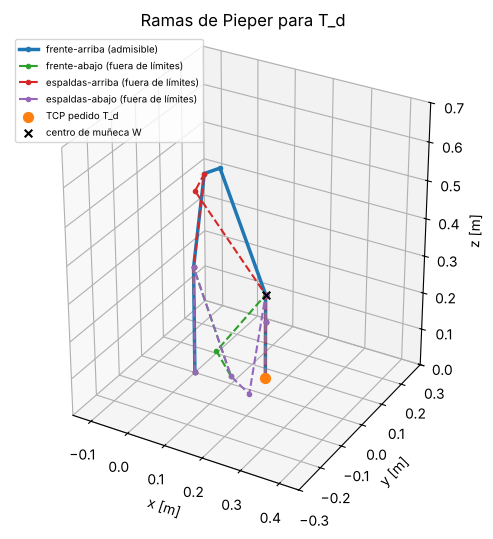

In [ ]:
nombre0, cands0 = next(iter(RAMAS.items()))
fig = plt.figure(figsize=(7, 5.5))
ax = fig.add_subplot(projection="3d")
colores = {"frente-arriba": "tab:blue", "frente-abajo": "tab:green", "espaldas-arriba": "tab:red", "espaldas-abajo": "tab:purple"}
vistos = set()
for c in cands0:
    clave = f"{c.brazo}-{c.codo}"
    if not c.real or clave in vistos:
        continue
    vistos.add(clave)
    P = np.array([T[:3, 3] for T in m.marcos(c.q)])
    adm = any(o.admisible for o in cands0 if o.brazo == c.brazo and o.codo == c.codo)
    ax.plot(P[:, 0], P[:, 1], P[:, 2], "-" if adm else "--", marker="o", markersize=3, linewidth=2.5 if adm else 1.5,
            color=colores[clave], label=f"{clave} ({'admisible' if adm else 'fuera de límites'})")
ax.scatter(*T_D[nombre0][:3, 3], color="tab:orange", s=50, label=f"TCP pedido {nombre0}")
ax.scatter(*pp.centro_muneca(T_D[nombre0]), color="k", s=30, marker="x", label="centro de muñeca W")
ax.set_xlabel("x [m]"); ax.set_ylabel("y [m]"); ax.set_zlabel("z [m]")
ax.set_xlim(-0.15, 0.45); ax.set_ylim(-0.3, 0.3); ax.set_zlim(0, 0.7)
ax.set_box_aspect((0.6, 0.6, 0.7)); ax.legend(loc="upper left", fontsize=7)
ax.set_title(f"Ramas de Pieper para {nombre0}")
fig.tight_layout(); fig.savefig(FIG / "P2_ramas_pieper.png", dpi=150); fig.savefig(FIG / "P2_ramas_pieper.pdf")
plt.show()

## 4. Selección de la configuración final $q_f$

No es lo mismo que la sección 3. La sección 3 responde **"¿la rama es correcta?"**: reinyecta cada candidato en la
FK. La sección 4 responde **"¿cuál de las correctas uso para mover el robot?"**. Como todas las ramas reales ya
pasaron la FK, la elección es un criterio **físico y práctico**, y la guía pide justificarla. La plantilla
(`seleccion_ramas.py`) trabaja en dos etapas:

**Etapa 1. Filtros obligatorios.** No se recalcula nada: se **reutiliza** lo que ya salió de las secciones 2.5 y 3
(los atributos `real`, `valida_fk` y `fuera_de_limites` de cada rama). Una rama que falla un filtro queda descartada
con puntaje 0, y se escribe el valor que la descartó.

| Filtro | Viene de | Condición |
|---|---|---|
| F1 real | sección 2.3 | $|k| \le 1$ |
| F2 FK | sección 3 | $e_p < 10^{-6}$ m y $e_R < 10^{-6}$ rad |
| F3 límites | sección 2.5 | $q_{j,\min} \le q_j \le q_{j,\max}$ (datasheet ABB) |

**Etapa 2. Índices de calidad** (cada uno de 0 = peor a 1 = mejor) y puntaje:

| Índice | Fórmula | Qué premia | Peso |
|---|---|---|---|
| $I_{lim}$ | $\min_j \dfrac{\min(q_j - q_{j,\min},\ q_{j,\max} - q_j)}{(q_{j,\max} - q_{j,\min})/2}$ | juntas lejos de sus topes | 0.25 |
| $I_{sing}$ | $|\sin q_5|$ | muñeca lejos de la singularidad $q_5 = 0$ | 0.25 |
| $I_{esp}$ | $\min\!\left(1,\ \dfrac{\min(z_{codo}, z_W)}{0.20\ \text{m}}\right)$ | codo y muñeca lejos de la mesa ($z = 0$) | 0.15 |
| $I_{mov}$ | $1 - \dfrac{\|W(q - q_i)\|}{\|W\pi\|}$, $W = \text{diag}(1,1,1,0.5,0.5,0.5)$ | menor movimiento desde $q_i$, más peso al brazo | 0.35 |

$$
\text{Puntaje} = 100\,\left(0.25\,I_{lim} + 0.25\,I_{sing} + 0.15\,I_{esp} + 0.35\,I_{mov}\right) \in [0, 100]
$$

Se elige la rama admisible de **mayor puntaje**. Los pesos son una decisión de diseño declarada: el movimiento pesa más
porque define la duración y el esfuerzo de la trayectoria LSPB. Para $q_6$ (rango ±400°) se usa el representante
$q_6 + 2\pi k$ más cercano a $q_i$.

In [ ]:
Q_F = {}
for nombre, candidatos in RAMAS.items():
    filas, elegida = sel.evaluar(candidatos, m.Q_I)
    sel.imprimir(nombre, filas)
    verificar(f"{nombre}: hay una configuración elegida", elegida is not None)
    Q_F[nombre] = elegida["q"]
    print(f"\n  → q_f({nombre}) = {np.round(np.rad2deg(elegida['q']), 2)} deg  (rama {elegida['rama']}, {elegida['puntaje']:.1f} puntos)")
    # Única FK nueva de esta sección: q6 puede haberse cambiado por q6 ± 360° (otro representante del mismo ángulo).
    verificar(f"{nombre}: q_f con su representante de q6 sigue reproduciendo T_d", max(pp.errores_pose(T_D[nombre], m.fk(Q_F[nombre]))) < 1e-6)
    print("=" * 100)


T_d
rama configuración           F1  F2  F3  I_lim I_sing I_esp I_mov  puntaje  estado    
--------------------------------------------------------------------------------------
   1 frente-arriba-q5+       sí  sí  sí   0.25    0.55   1.00   0.72     60.4  ELEGIDA   
   2 frente-arriba-q5-       sí  sí  no   0.00    0.55   1.00   0.70      0.0  descartada
   3 frente-abajo-q5+        sí  sí  no   0.00    0.61   0.30   0.30      0.0  descartada
   4 frente-abajo-q5-        sí  sí  no   0.00    0.61   0.30   0.29      0.0  descartada
   5 espaldas-arriba-q5+     sí  sí  no   0.00    0.86   1.00   0.27      0.0  descartada
   6 espaldas-arriba-q5-     sí  sí  no   0.00    0.86   1.00   0.35      0.0  descartada
   7 espaldas-abajo-q5+      sí  sí  no   0.00    0.20   0.30   0.24      0.0  descartada
   8 espaldas-abajo-q5-      sí  sí  no   0.00    0.20   0.30   0.32      0.0  descartada

Motivo de cada decisión:
  rama 1: mayor puntaje entre las admisibles
  rama 2: F3: q4 = -180.0° fue

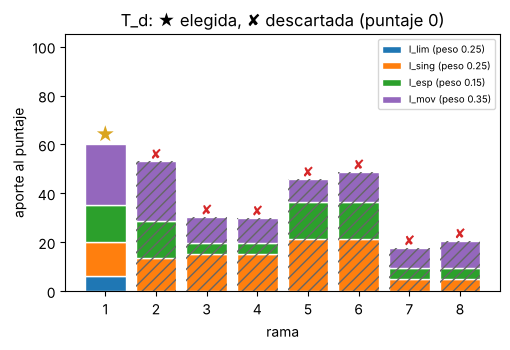

Las barras rayadas muestran cuánto sumarían los índices si la rama no estuviera descartada por un filtro.


In [ ]:
# Gráfica de la plantilla: aporte de cada índice al puntaje de las ramas reales.
fig, axs = plt.subplots(1, len(RAMAS), figsize=(5.2 * len(RAMAS), 3.6), squeeze=False)
colores = {"I_lim": "tab:blue", "I_sing": "tab:orange", "I_esp": "tab:green", "I_mov": "tab:purple"}
for ax, (nombre, candidatos) in zip(axs[0], RAMAS.items()):
    filas, elegida = sel.evaluar(candidatos, m.Q_I)
    x = np.arange(1, 9)
    base = np.zeros(8)
    for k, w in sel.PESOS.items():
        v = np.array([100 * w * f["indices"][k] if f["indices"] else 0.0 for f in filas])
        ax.bar(x, v, bottom=base, color=colores[k], label=f"{k} (peso {w})", edgecolor="white")
        base += v
    for f in filas:
        if f["estado"] == "descartada":
            ax.bar(f["rama"], base[f["rama"] - 1], fill=False, hatch="///", edgecolor="0.4", linewidth=0)
            ax.text(f["rama"], base[f["rama"] - 1] + 1, "✘", ha="center", color="tab:red")
    ax.text(elegida["rama"], base[elegida["rama"] - 1] + 1, "★", ha="center", fontsize=14, color="goldenrod")
    ax.set_xticks(x); ax.set_xlabel("rama"); ax.set_ylabel("aporte al puntaje"); ax.set_ylim(0, 105)
    ax.set_title(f"{nombre}: ★ elegida, ✘ descartada (puntaje 0)")
axs[0][0].legend(fontsize=7, loc="upper right")
fig.tight_layout(); fig.savefig(FIG / "P3_seleccion_ramas.png", dpi=150); fig.savefig(FIG / "P3_seleccion_ramas.pdf")
plt.show()
print("Las barras rayadas muestran cuánto sumarían los índices si la rama no estuviera descartada por un filtro.")

## 5. Trayectoria LSPB de $q_i$ a $q_f$

Pieper entrega solo el destino $q_f$. Dos configuraciones no definen *cómo* moverse: hace falta una **trayectoria**
parametrizada en el tiempo, $q(t),\ \dot q(t),\ \ddot q(t)$, porque de ella dependen la velocidad, la aceleración y,
más adelante, el torque de los motores (*W09-S01, diapositiva 7*).

### 5.1 Ecuaciones de clase (una junta)

El LSPB (*Linear Segment with Parabolic Blends*) da un perfil de velocidad **trapezoidal**: arranca con aceleración
constante $\ddot q_c$, sigue a velocidad constante $\dot q_c$ y frena con $-\ddot q_c$. Supuestos: reposo en los
extremos $\dot q(0) = \dot q(t_f) = 0$ (*W09-S01, diapositiva 8*):

| Fase | Intervalo | $q(t)$ | $\dot q(t)$ | $\ddot q(t)$ |
|---|---|---|---|---|
| 1. Aceleración | $0 \le t \le t_c$ | $q_i + \tfrac12 \ddot q_c t^2$ | $\ddot q_c\, t$ | $\ddot q_c$ |
| 2. Vel. constante | $t_c < t \le t_f - t_c$ | $q_i + \dot q_c\,(t - \tfrac{t_c}{2})$ | $\dot q_c = \ddot q_c t_c$ | $0$ |
| 3. Desaceleración | $t_f - t_c < t \le t_f$ | $q_f - \tfrac12 \ddot q_c (t_f - t)^2$ | $\ddot q_c (t_f - t)$ | $-\ddot q_c$ |

Tiempo de mezcla y condición de factibilidad (*W09-S01, diapositiva 9; hoja de trabajo LSPB W09-S01*):

$$
t_c = \frac{t_f}{2} - \frac12\sqrt{t_f^2 - \frac{4(q_f - q_i)}{\ddot q_c}},
\qquad
|\ddot q_c| \ge \frac{4\,|q_f - q_i|}{t_f^2}
$$

Con la igualdad desaparece el tramo de velocidad constante y el perfil de velocidad es triangular. $q$ y $\dot q$ son
continuas; $\ddot q$ tiene saltos en $t_c$ y $t_f - t_c$, lo que es aceptable en el modelo básico (*hoja de trabajo
LSPB, parte B*).

**Comprobación con el ejemplo guiado de clase** ($q_i = 0$, $q_f = 2$ rad, $t_f = 3$ s, $\ddot q_c = 1$ rad/s²): la
diapositiva 10 da $|\ddot q_c|_{\min} = 8/9$, $t_c = 1$ s y $\dot q_c = 1$ rad/s.

In [ ]:
a_min = lspb.aceleracion_minima(0.0, 2.0, 3.0)
tc_ej = lspb.tiempo_mezcla(0.0, 2.0, 3.0, 1.0)
print(f"|q̈c|_min = {a_min:.4f} rad/s² (8/9 = {8/9:.4f}),  tc = {tc_ej:.4f} s,  q̇c = q̈c·tc = {1.0 * tc_ej:.4f} rad/s")
verificar("el código reproduce el ejemplo guiado de clase (tc = 1 s, q̇c = 1 rad/s)", np.isclose(a_min, 8/9) and np.isclose(tc_ej, 1.0))

|q̈c|_min = 0.8889 rad/s² (8/9 = 0.8889),  tc = 1.0000 s,  q̇c = q̈c·tc = 1.0000 rad/s
✔ el código reproduce el ejemplo guiado de clase (tc = 1 s, q̇c = 1 rad/s)


### 5.2 Seis juntas sincronizadas

La clase trata una sola junta. El robot mueve las seis a la vez y deben **empezar y terminar juntas**, si no el TCP
seguiría un camino raro y cada motor terminaría en un instante distinto. Se usa la extensión estándar
(Siciliano et al., 2009, sec. 4.2.1): **mismo $t_f$ y mismo $t_c$ para todas**, y cada junta ajusta su
$\ddot q_c$.

1. **Tiempo mínimo de cada junta** con su $v_{\max}$ y $a_{\max}$. Si $|D| \ge v_{\max}^2 / a_{\max}$ alcanza la
   velocidad máxima (trapecio) y $t_{f,j} = |D|/v_{\max} + v_{\max}/a_{\max}$; si no, el perfil es triangular y
   $t_{f,j} = 2\sqrt{|D|/a_{\max}}$, con $D = q_f - q_i$.
2. **Junta crítica:** la de mayor $t_{f,j}$. Ella fija $t_f$ (redondeado hacia arriba a 0.01 s).
3. **Tiempo de mezcla común** con la fórmula de clase, usando en la junta crítica su $\ddot q_c = a_{\max}$.
4. **Cada junta:** al exigir que la posición sea continua en $t = t_f - t_c$ (fin del tramo 2 = inicio del tramo 3):

$$
q_i + \dot q_c\left(t_f - \tfrac{3t_c}{2}\right) = q_f - \tfrac12 \ddot q_c t_c^2
\;\;\xrightarrow{\ \dot q_c = \ddot q_c t_c\ }\;\;
D = \ddot q_c\, t_c\,(t_f - t_c)
\;\;\Rightarrow\;\;
\dot q_c = \frac{D}{t_f - t_c},\qquad \ddot q_c = \frac{\dot q_c}{t_c}
$$

Como las demás juntas recorren menos en el mismo tiempo, sus $\dot q_c$ y $\ddot q_c$ quedan por debajo de sus
límites.

### 5.3 Límites y supuestos

- $v_{\max}$: datasheet ABB por eje (250, 250, 250, 320, 320, 420 °/s), al **25 %**, como un *override* de velocidad
  conservador para pruebas.
- $a_{\max}$: **ABB no publica aceleraciones articulares.** Supuesto declarado: cada eje alcanza su $v_{\max}$ en
  $0.25$ s, es decir $a_{\max} = v_{\max} / 0.25$ s. Se puede cambiar en `lspb.py` (`ESCALA_VEL`, `T_RAMPA_S`).

In [ ]:
print(f"{'junta':>5} {'vmax datasheet [°/s]':>21} {'vmax usada [°/s]':>17} {'amax supuesta [°/s²]':>21}")
for j in range(6):
    print(f"{'q' + str(j+1):>5} {m.VMAX_DEG_S[j]:21.0f} {np.rad2deg(lspb.VMAX[j]):17.1f} {np.rad2deg(lspb.AMAX[j]):21.1f}")

junta  vmax datasheet [°/s]  vmax usada [°/s]  amax supuesta [°/s²]
   q1                   250              62.5                 250.0
   q2                   250              62.5                 250.0
   q3                   250              62.5                 250.0
   q4                   320              80.0                 320.0
   q5                   320              80.0                 320.0
   q6                   420             105.0                 420.0


### 5.4 Parámetros de la trayectoria

Para la pose objetivo se planifica el movimiento desde la configuración inicial $q_i$ hasta el $q_f$ elegido en la
sección 4. La tabla documenta lo que pide la guía: configuración inicial y final, tiempo total, aceleración y tiempo
de mezcla de cada junta.

In [ ]:
TRAY = {}
for nombre, q_f in Q_F.items():
    tr = lspb.LSPB(m.Q_I, q_f)
    TRAY[nombre] = tr
    print(f"\n{nombre}:  t_f = {tr.tf:.2f} s,  t_c = {tr.tc:.4f} s,  tramo a vel. constante = {tr.tf - 2 * tr.tc:.4f} s,  junta crítica = q{tr.critica + 1}")
    print(f"{'junta':>5} {'q_i [°]':>8} {'q_f [°]':>8} {'D [°]':>8} {'t_f,j min [s]':>13} {'|q̈c|min [°/s²]':>15} {'q̈c [°/s²]':>10} {'t_c fórmula [s]':>15} {'q̇c [°/s]':>9} {'q̇c/vmax':>8} {'q̈c/amax':>8}")
    for j in range(6):
        D = tr.D[j]
        tc_j = lspb.tiempo_mezcla(tr.q_i[j], tr.q_f[j], tr.tf, tr.qdd_c[j]) if D != 0 else float("nan")
        print(f"{'q' + str(j+1):>5} {np.rad2deg(tr.q_i[j]):8.2f} {np.rad2deg(tr.q_f[j]):8.2f} {np.rad2deg(D):8.2f} {tr.tf_min[j]:13.4f} "
              f"{np.rad2deg(lspb.aceleracion_minima(tr.q_i[j], tr.q_f[j], tr.tf)):15.2f} {np.rad2deg(tr.qdd_c[j]):10.2f} {tc_j:15.4f} "
              f"{np.rad2deg(tr.qd_c[j]):9.2f} {abs(tr.qd_c[j]) / tr.vmax[j]:8.3f} {abs(tr.qdd_c[j]) / tr.amax[j]:8.3f}")


T_d:  t_f = 1.76 s,  t_c = 0.2493 s,  tramo a vel. constante = 1.2613 s,  junta crítica = q6
junta  q_i [°]  q_f [°]    D [°] t_f,j min [s] |q̈c|min [°/s²] q̈c [°/s²] t_c fórmula [s] q̇c [°/s] q̇c/vmax q̈c/amax
   q1     0.00   -21.80   -21.80        0.5988           28.15     -57.88          0.2493    -14.43    0.231    0.232
   q2     0.00     9.63     9.63        0.3925           12.43      25.56          0.2493      6.37    0.102    0.102
   q3     0.00    47.13    47.13        1.0041           60.86     125.12          0.2493     31.20    0.499    0.500
   q4     0.00    -0.00    -0.00        0.0000            0.00      -0.00          0.2493     -0.00    0.000    0.000
   q5     0.00    33.24    33.24        0.6656           42.93      88.26          0.2493     22.01    0.275    0.276
   q6     0.00   158.20   158.20        1.7567          204.29     420.00          0.2493    104.72    0.997    1.000


**Lectura de la tabla.** La junta crítica es la que más tarda con sus propios límites; usa casi el 100 % de su
$v_{\max}$ y su $a_{\max}$. Las demás se estiran al mismo $t_f$ y usan una fracción de sus límites. La columna
"$t_c$ fórmula" aplica la ecuación de clase a cada junta con su propio $\ddot q_c$ y devuelve el mismo $t_c$ para
todas, lo que confirma la sincronización. En cada junta $|\ddot q_c| \ge |\ddot q_c|_{\min}$, así que el perfil existe.

### 5.5 Perfiles $q(t)$, $\dot q(t)$, $\ddot q(t)$ alineados

Las tres gráficas comparten el eje de tiempo para leer las fases en vertical (*matriz diagnóstica W10-S01*: "alinee los
gráficos de $q$, $\dot q$, $\ddot q$"). Las bandas marcan las fases: aceleración, velocidad constante y desaceleración.
Es la **velocidad** la que tiene forma de trapecio, no la posición.

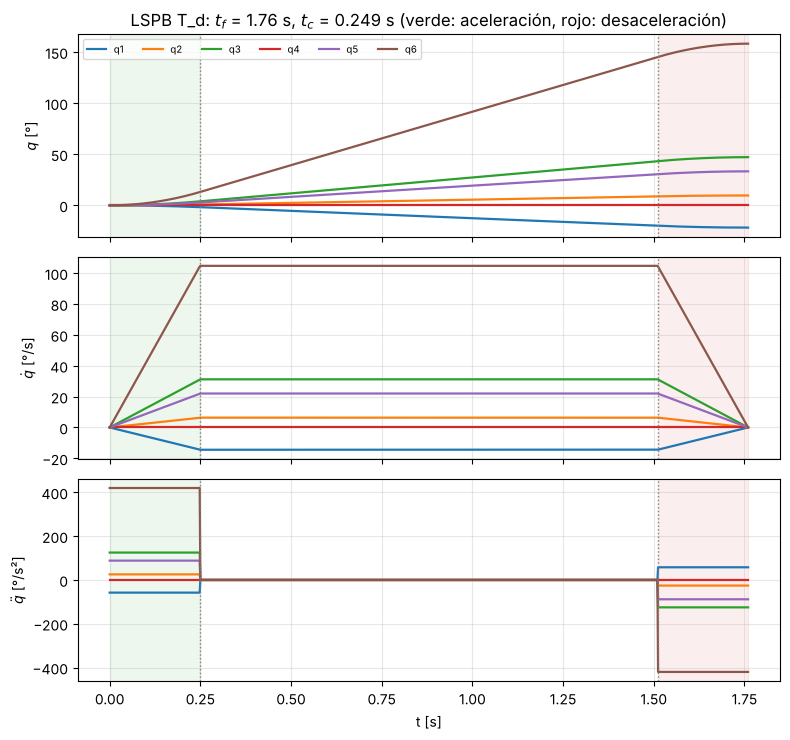

In [ ]:
for nombre, tr in TRAY.items():
    t, q, qd, qdd = tr.muestrear()
    fig, axs = plt.subplots(3, 1, figsize=(8, 7.5), sharex=True)
    datos = [(np.rad2deg(q), "$q$ [°]"), (np.rad2deg(qd), r"$\dot q$ [°/s]"), (np.rad2deg(qdd), r"$\ddot q$ [°/s²]")]
    for ax, (y, etiqueta) in zip(axs, datos):
        for j in range(6):
            ax.plot(t, y[:, j], color=plt.cm.tab10(j), linewidth=1.6, label=f"q{j+1}")
        ax.axvspan(0, tr.tc, color="tab:green", alpha=0.08)
        ax.axvspan(tr.tf - tr.tc, tr.tf, color="tab:red", alpha=0.08)
        for x in (tr.tc, tr.tf - tr.tc):
            ax.axvline(x, color="0.5", linestyle=":", linewidth=1)
        ax.set_ylabel(etiqueta); ax.grid(alpha=0.3)
    axs[0].legend(ncol=6, fontsize=7, loc="upper left")
    axs[0].set_title(f"LSPB {nombre}: $t_f$ = {tr.tf:.2f} s, $t_c$ = {tr.tc:.3f} s (verde: aceleración, rojo: desaceleración)")
    axs[2].set_xlabel("t [s]")
    fig.tight_layout(); fig.savefig(FIG / f"P5_lspb_{nombre}.png", dpi=150); fig.savefig(FIG / f"P5_lspb_{nombre}.pdf")
    plt.show()

### 5.6 Verificaciones

La guía exige validar las **condiciones de frontera** (reposo al inicio y al final). Además se comprueba la
continuidad, los límites, que el área bajo $\dot q(t)$ sea el desplazamiento y que el robot termine en $T_d$.

In [ ]:
for nombre, tr in TRAY.items():
    q0, qd0, _ = tr.evaluar(0.0)
    q1, qd1, _ = tr.evaluar(tr.tf)
    verificar(f"{nombre}: q(0) = q_i y q(t_f) = q_f", np.allclose(q0, tr.q_i, atol=1e-12) and np.allclose(q1, tr.q_f, atol=1e-12))
    verificar(f"{nombre}: reposo en las fronteras, q̇(0) = q̇(t_f) = 0", np.allclose(qd0, 0, atol=1e-12) and np.allclose(qd1, 0, atol=1e-12))
    eps, salto_q, salto_qd = 1e-9, 0.0, 0.0
    for tk in (tr.tc, tr.tf - tr.tc):
        a, b = tr.evaluar(tk - eps), tr.evaluar(tk + eps)
        salto_q, salto_qd = max(salto_q, np.abs(a[0] - b[0]).max()), max(salto_qd, np.abs(a[1] - b[1]).max())
    verificar(f"{nombre}: q y q̇ continuas en t_c y t_f − t_c (saltos {salto_q:.1e}, {salto_qd:.1e})", salto_q < 1e-6 and salto_qd < 1e-6)
    verificar(f"{nombre}: |q̇c| ≤ vmax y |q̈c| ≤ amax en las 6 juntas",
              np.all(np.abs(tr.qd_c) <= tr.vmax + 1e-12) and np.all(np.abs(tr.qdd_c) <= tr.amax + 1e-12))
    verificar(f"{nombre}: |q̈c| ≥ 4|D|/t_f² en cada junta (el perfil existe)",
              np.all(np.abs(tr.qdd_c) >= lspb.aceleracion_minima(tr.q_i, tr.q_f, tr.tf) - 1e-12))
    verificar(f"{nombre}: t_c ≤ t_f / 2", tr.tc <= tr.tf / 2)
    t, q, qd, _ = tr.muestrear(20001)
    area = np.sum((qd[1:] + qd[:-1]) / 2 * np.diff(t)[:, None], axis=0)
    verificar(f"{nombre}: el área bajo q̇(t) es el desplazamiento D (error {np.abs(area - tr.D).max():.1e} rad)", np.allclose(area, tr.D, atol=1e-6))
    verificar(f"{nombre}: el TCP termina en T_d", max(pp.errores_pose(T_D[nombre], m.fk(q1))) < 1e-6)
    print()

✔ T_d: q(0) = q_i y q(t_f) = q_f
✔ T_d: reposo en las fronteras, q̇(0) = q̇(t_f) = 0
✔ T_d: q y q̇ continuas en t_c y t_f − t_c (saltos 3.7e-09, 7.3e-09)
✔ T_d: |q̇c| ≤ vmax y |q̈c| ≤ amax en las 6 juntas
✔ T_d: |q̈c| ≥ 4|D|/t_f² en cada junta (el perfil existe)
✔ T_d: t_c ≤ t_f / 2
✔ T_d: el área bajo q̇(t) es el desplazamiento D (error 1.3e-08 rad)
✔ T_d: el TCP termina en T_d



## 6. Jacobiano geométrico y singularidades

El Jacobiano relaciona las velocidades articulares con la **velocidad espacial (twist)** del TCP: velocidad lineal
arriba y angular abajo, las dos en el marco base (*W08-S01, diapositivas 2 y 5*, convención de Siciliano et al.):

$$
\dot x = \begin{bmatrix} v \\ \omega \end{bmatrix} = J(q)\,\dot q, \qquad J \in \mathbb{R}^{6\times 6}
$$

Lo que pide la guía (*Guía oficial Hito 2, sec. 3.3* y rúbrica D, 20 %): implementar $\dot x = J(q)\dot q$; un
**experimento computacional independiente** con una secuencia de poses hacia una singularidad conocida; **registrar
la pérdida de rango** $\operatorname{rank}J(q) < \operatorname{rank}_{\max}$, **graficarla**, **interpretar la movilidad
perdida** y **analizar la amplificación de velocidad**. Excelencia: "experimento de aproximación claro; interpreta
rango y movilidad perdida".

Todo se evalúa sobre la misma $T_d$, su $q_f$ y la trayectoria LSPB de la sección 5.

In [ ]:
import jacobiano as jb

QF, TR = Q_F["T_d"], TRAY["T_d"]
print("q_f [°] =", np.round(np.rad2deg(QF), 3))

q_f [°] = [-21.801   9.627  47.128  -0.     33.245 158.199]


### 6.1 Construcción columna a columna

Si solo gira la junta $i$ (de revolución), el robot desde ese eslabón en adelante rota como un sólido rígido
alrededor del eje $z_{i-1}$, que pasa por $o_{i-1}$. La velocidad del TCP es $\omega_i\times r_i$ con
$r_i = p_{TCP} - o_{i-1}$ (*W08-S01, diapositivas 6 y 7*; Siciliano et al., 2009, sec. 3.1.3):

$$
J_i = \begin{bmatrix} J_{v,i} \\ J_{\omega,i}\end{bmatrix} = \begin{bmatrix} z_{i-1}\times(p_{TCP} - o_{i-1}) \\ z_{i-1}\end{bmatrix},
\qquad \dot x = \sum_{i=1}^{6} J_i\,\dot q_i
$$

$z_{i-1}$ es la tercera columna de $R_0^{i-1}$ y $o_{i-1}$ la traslación de $T_0^{i-1}$; los dos salen de la misma
FK de la sección 1 (`m.marcos(q)`), así que **todos los vectores están en el marco base {0}**, como exige la regla de
marcos del producto cruz (*W08-S02, diapositiva 3*). Código: `jacobiano.py`, función `jacobiano(q)`.

In [ ]:
J_f = jb.jacobiano(QF)
print("J(q_f)  (filas: vx vy vz [m/s], wx wy wz [rad/s]; columnas: q̇1..q̇6 en rad/s)\n")
print(np.round(J_f, 4))

J(q_f)  (filas: vx vy vz [m/s], wx wy wz [rad/s]; columnas: q̇1..q̇6 en rad/s)

[[ 0.1    -0.1578 -0.405   0.0452 -0.2061  0.    ]
 [ 0.25    0.0631  0.162   0.113   0.0824  0.    ]
 [-0.     -0.2693 -0.2241 -0.     -0.     -0.    ]
 [ 0.      0.3714  0.3714  0.509   0.3714  0.    ]
 [ 0.      0.9285  0.9285 -0.2036  0.9285 -0.    ]
 [ 1.      0.      0.     -0.8363 -0.     -1.    ]]


### 6.2 Verificación a mano en $q = q_i = 0$

Se elige $q_i = 0$ porque es el **primer punto de la trayectoria** y sus marcos se leen directo de la figura de la
sección 1.5. En $q = 0$ el TCP está en $p = (0.302 + 0.072 + 0.150,\ 0,\ 0.290 + 0.270 + 0.070) = (0.524,\ 0,\ 0.630)$ m:

| $i$ | $z_{i-1}$ | $o_{i-1}$ | $p - o_{i-1}$ | $J_{v,i} = z_{i-1}\times(p - o_{i-1})$ | $J_{\omega,i}$ |
|---|---|---|---|---|---|
| 1 | (0, 0, 1) | (0, 0, 0) | (0.524, 0, 0.630) | (0, 0.524, 0) | (0, 0, 1) |
| 2 | (0, 1, 0) | (0, 0, 0.290) | (0.524, 0, 0.340) | (0.340, 0, −0.524) | (0, 1, 0) |
| 3 | (0, 1, 0) | (0, 0, 0.560) | (0.524, 0, 0.070) | (0.070, 0, −0.524) | (0, 1, 0) |
| 4 | (1, 0, 0) | (0, 0, 0.630) | (0.524, 0, 0) | (0, 0, 0) | (1, 0, 0) |
| 5 | (0, 1, 0) | (0.302, 0, 0.630) | (0.222, 0, 0) | (0, 0, −0.222) | (0, 1, 0) |
| 6 | (1, 0, 0) | (0.302, 0, 0.630) | (0.222, 0, 0) | (0, 0, 0) | (1, 0, 0) |

Mismo procedimiento que el problema diagnóstico del 2R (*W08-S02, diapositivas 4 a 6*). Ejemplo de la columna 2: $(0,1,0)\times(0.524,0,0.340) = (1\cdot0.340 - 0\cdot0,\ 0\cdot0.524 - 0\cdot0.340,\ 0\cdot0 - 1\cdot0.524) = (0.340,\ 0,\ -0.524)$.

**Lectura física.** Girar la base mueve el TCP en $+y$ a 0.524 m/s por rad/s (radio 0.524 m). El hombro y el codo lo
llevan hacia adelante y abajo. Las juntas 4 y 6 tienen el TCP **sobre su eje**: no lo trasladan, solo lo giran.
Además las columnas 4 y 6 son **idénticas**: $q_i = 0$ es una **singularidad de muñeca** (se estudia en 6.5).

Como segunda validación, independiente de la fórmula $z\times(p-o)$, se deriva la FK por **diferencias finitas
centradas**: $J_{v,i} \approx [p(q+he_i) - p(q-he_i)]/2h$ y, como $\dot R R^T = [\omega]_\times$ (Siciliano, sec. 3.1.1),
$[J_{\omega,i}]_\times \approx [R(q+he_i) - R(q-he_i)]/2h \cdot R^T$.

In [ ]:
J_mano = np.array([
    [0.000,  0.340,  0.070, 0, 0.000, 0],
    [0.524,  0.000,  0.000, 0, 0.000, 0],
    [0.000, -0.524, -0.524, 0, -0.222, 0],
    [0, 0, 0, 1, 0, 1],
    [0, 1, 1, 0, 1, 0],
    [1, 0, 0, 0, 0, 0]], dtype=float)
J_0 = jb.jacobiano(m.Q_I)
print("J(q_i) calculado por el código:\n", np.round(J_0, 4))
verificar(f"J(q_i) coincide con el cálculo a mano (dif. máx {np.abs(J_0 - J_mano).max():.1e})", np.allclose(J_0, J_mano, atol=1e-12))

rng = np.random.default_rng(6)
muestras = [QF] + [rng.uniform(m.LIMITES_RAD[:, 0], m.LIMITES_RAD[:, 1]) for _ in range(200)]
err_fd = max(np.abs(jb.jacobiano(q) - jb.jacobiano_numerico(q)).max() for q in muestras)
verificar(f"J = diferencias finitas de la FK en q_f y 200 posturas aleatorias (dif. máx {err_fd:.1e})", err_fd < 1e-8)

J(q_i) calculado por el código:
 [[-0.     0.34   0.07   0.    -0.     0.   ]
 [ 0.524  0.     0.    -0.     0.    -0.   ]
 [ 0.    -0.524 -0.524 -0.    -0.222 -0.   ]
 [ 0.     0.     0.     1.     0.     1.   ]
 [ 0.     1.     1.     0.     1.     0.   ]
 [ 1.     0.     0.    -0.     0.    -0.   ]]
✔ J(q_i) coincide con el cálculo a mano (dif. máx 1.1e-16)


✔ J = diferencias finitas de la FK en q_f y 200 posturas aleatorias (dif. máx 3.2e-10)


### 6.3 Interpretación de las columnas en $q_f$

La columna $i$ es **la velocidad que se induciría en el TCP si la junta $i$ girara a 1 rad/s y las demás estuvieran
fijas** (*W08-S02, diapositiva 7*). $\lVert J_{v,i}\rVert$
es la distancia del TCP al eje $i$ (brazo de palanca), y $J_{\omega,i}$ es el eje $z_{i-1}$.

In [ ]:
T_f = m.marcos(QF)
print(f"{'junta':>5} {'|J_v,i| [m/s por rad/s]':>24} {'J_w,i = z_(i-1)':>26}   papel")
for i in range(6):
    papel = "posiciona (palanca grande)" if np.linalg.norm(J_f[:3, i]) > 0.25 else "orienta (palanca chica)"
    print(f"{'q' + str(i+1):>5} {np.linalg.norm(J_f[:3, i]):24.4f}   {str(np.round(J_f[3:, i], 3)):>24}   {papel}")

junta  |J_v,i| [m/s por rad/s]            J_w,i = z_(i-1)   papel
   q1                   0.2693                 [0. 0. 1.]   posiciona (palanca grande)
   q2                   0.3184        [0.371 0.928 0.   ]   posiciona (palanca grande)
   q3                   0.4904        [0.371 0.928 0.   ]   posiciona (palanca grande)
   q4                   0.1217     [ 0.509 -0.204 -0.836]   orienta (palanca chica)
   q5                   0.2220     [ 0.371  0.928 -0.   ]   orienta (palanca chica)
   q6                   0.0000              [ 0. -0. -1.]   orienta (palanca chica)


Las juntas 1 a 3 tienen palancas de varios decímetros: son las que **posicionan** el TCP. Las juntas 4 a 6 tienen
sus ejes cerca del TCP (palanca $\le 0.222$ m, la distancia W → TCP): sobre todo **orientan** la herramienta. Es la
misma separación brazo / muñeca que usó Pieper.

### 6.4 El Jacobiano sobre la trayectoria LSPB

Se evalúa $\dot x(t) = J(q(t))\,\dot q(t)$ con la trayectoria de la sección 5. Como validación, la velocidad lineal
se compara con la derivada numérica centrada de la posición que da la FK, $[p(q(t+h)) - p(q(t-h))]/2h$. En cada instante se calcula también el
**rango** y el menor valor singular $\sigma_6$ de $J$ (ver 6.5).

✔ v = J q̇ coincide con la derivada numérica de p(q(t)) (dif. máx 1.9e-10 m/s)

|v| máx = 0.452 m/s,  |w| máx = 2.323 rad/s
rango de J: 5 en t = 0 (q_i, muñeca singular); 6 desde t = 0.0029 s hasta t_f
σ6 crece a medida que q5 se aleja de 0: σ6(t_c) = 0.0093,  σ6(t_f / 2) = 0.0679,  σ6(t_f) = 0.1715


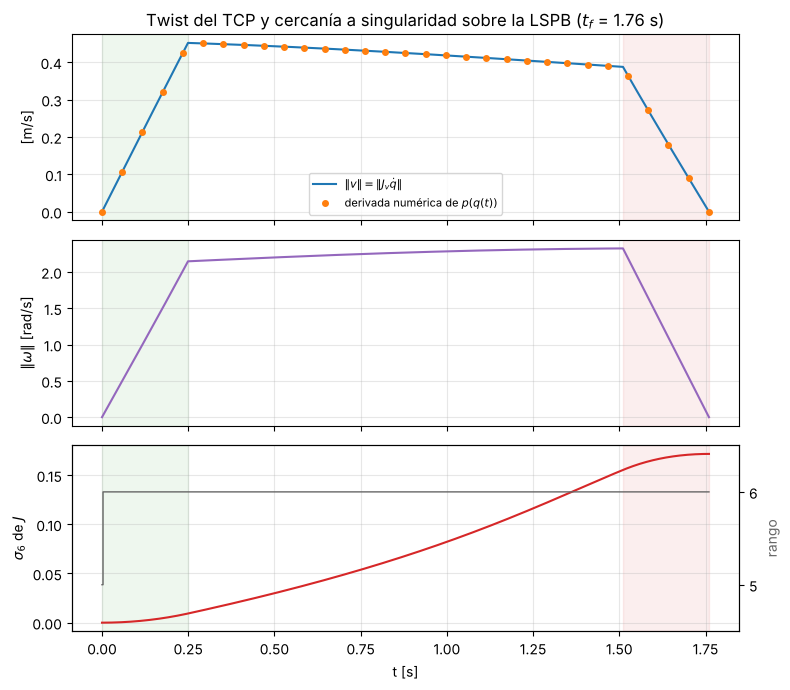

In [ ]:
t, q_t, qd_t, _ = TR.muestrear(1201)
twist = np.array([jb.jacobiano(qk) @ qdk for qk, qdk in zip(q_t, qd_t)])
p_t = np.array([m.fk(qk)[:3, 3] for qk in q_t])
H = 1e-6
v_num = np.array([(m.fk(TR.evaluar(tk + H)[0])[:3, 3] - m.fk(TR.evaluar(tk - H)[0])[:3, 3]) / (2 * H) for tk in t])
rangos = np.array([jb.analisis_rango(jb.jacobiano(qk))["rango"] for qk in q_t])
sig6 = np.array([jb.analisis_rango(jb.jacobiano(qk))["sigma"][-1] for qk in q_t])

err_v = np.abs(twist[:, :3] - v_num)[1:-1].max()
verificar(f"v = J q̇ coincide con la derivada numérica de p(q(t)) (dif. máx {err_v:.1e} m/s)", err_v < 1e-6)
i_reg = np.argmax(rangos == 6)
print(f"\n|v| máx = {np.linalg.norm(twist[:, :3], axis=1).max():.3f} m/s,  |w| máx = {np.linalg.norm(twist[:, 3:], axis=1).max():.3f} rad/s")
print(f"rango de J: {rangos[0]} en t = 0 (q_i, muñeca singular); 6 desde t = {t[i_reg]:.4f} s hasta t_f")
print(f"σ6 crece a medida que q5 se aleja de 0: σ6(t_c) = {sig6[np.argmin(abs(t - TR.tc))]:.4f},  σ6(t_f / 2) = {sig6[len(t) // 2]:.4f},  σ6(t_f) = {sig6[-1]:.4f}")

fig, axs = plt.subplots(3, 1, figsize=(8, 7), sharex=True)
axs[0].plot(t, np.linalg.norm(twist[:, :3], axis=1), label=r"$\|v\| = \|J_v\dot q\|$")
axs[0].plot(t[::40], np.linalg.norm(v_num, axis=1)[::40], "o", ms=4, label="derivada numérica de $p(q(t))$")
axs[0].set_ylabel("[m/s]"); axs[0].legend(fontsize=8)
axs[1].plot(t, np.linalg.norm(twist[:, 3:], axis=1), color="tab:purple")
axs[1].set_ylabel(r"$\|\omega\|$ [rad/s]")
axs[2].plot(t, sig6, color="tab:red"); axs[2].set_ylabel(r"$\sigma_6$ de $J$")
ax2 = axs[2].twinx(); ax2.step(t, rangos, color="0.4", where="post", linewidth=1); ax2.set_ylabel("rango", color="0.4")
ax2.set_ylim(4.5, 6.5); ax2.set_yticks([5, 6])
for ax in axs:
    ax.axvspan(0, TR.tc, color="tab:green", alpha=0.08); ax.axvspan(TR.tf - TR.tc, TR.tf, color="tab:red", alpha=0.08)
    ax.grid(alpha=0.3)
axs[0].set_title(f"Twist del TCP y cercanía a singularidad sobre la LSPB ($t_f$ = {TR.tf:.2f} s)")
axs[2].set_xlabel("t [s]")
fig.tight_layout(); fig.savefig(FIG / "P6_jacobiano_trayectoria.png", dpi=150); fig.savefig(FIG / "P6_jacobiano_trayectoria.pdf")
plt.show()

**Lectura.** El robot **arranca en una singularidad de muñeca** ($q_i = 0$ tiene $q_5 = 0$): en $t = 0$ el rango es 5.
Apenas $q_5$ se mueve, $\sigma_6$ crece y el rango vuelve a 6. Eso no causa ningún problema porque la trayectoria es
**articular**: nunca se invierte $J$, solo se multiplica $J\dot q$, y además el robot está en reposo ($\dot q = 0$).
Distinto sería pedir una trayectoria **cartesiana** que pase por ahí (sección 6.6).

### 6.5 Singularidades del IRB 120: criterio de rango

$q^*$ es singular si $\operatorname{rank} J(q^*) < \operatorname{rank}_{\max} = \min(6, 6) = 6$ (*W08-S02, diapositiva 10*;
*Referencia visual de singularidades W08, criterio A*): el rango cuenta las direcciones instantáneas independientes en
que el TCP puede moverse, así que existe al menos un twist $[v;\omega]$ que **no puede generar** con ningún $\dot q$.
El rango numérico se mide con la descomposición en valores singulares (Siciliano et al., 2009, sec. 3.9; es lo que
hace `np.linalg.matrix_rank` del *ejemplo Python de rango, W08-S02*):

$$
J = U\Sigma V^T = \sum_{i=1}^{6}\sigma_i u_i v_i^T,\qquad \sigma_1\ge\dots\ge\sigma_6\ge 0,\qquad
\text{rango numérico} = \#\{\sigma_i > 10^{-6}\}
$$

Si $\sigma_6 = 0$, $u_6$ es la **dirección cartesiana perdida** y $v_6$ un **movimiento articular nulo** (mueve las
juntas sin mover el TCP), porque $Jv_6 = \sigma_6 u_6$.

**El determinante solo como complemento.** $\det J = 0$ prueba singularidad solo porque $J$ es cuadrada (6×6); la
definición universal es la pérdida de rango (*W08-S02, diapositiva 11*; *Referencia visual W08, criterio B*).
$\det J = \prod\sigma_i$ no dice cuántas
ni cuáles direcciones se pierden y su valor depende de las unidades (mezcla m y rad). Sirve para **ubicar** las
singularidades: con el punto de referencia en el centro de muñeca W, las juntas 4 a 6 no mueven W y $J$ queda
triangular por bloques (desacople de singularidades, Siciliano, sec. 3.3.1):

$$
J_W = \begin{bmatrix} J_{11} & 0 \\ J_{21} & J_{22}\end{bmatrix} \;\Rightarrow\;
\det J = \underbrace{L_2 L_3\cos(q_3-\delta)\,r_W}_{\det J_{11}\ \text{(brazo)}}\cdot\underbrace{(-\sin q_5)}_{\det J_{22}\ \text{(muñeca)}}
$$

con $L_2 = 0.270$ m, $L_3 = 0.310$ m, $\delta = 13.05°$ (los de Pieper) y $r_W$ la distancia horizontal con signo de W
al eje 1. Cambiar el punto de referencia del TCP a W no cambia el determinante (Siciliano, sec. 3.3.1).

In [ ]:
razon = [np.linalg.det(jb.jacobiano(q)) / np.prod(jb.det_factorizado(q)) for q in muestras[1:]]
verificar(f"det J = L2 L3 cos(q3-δ) r_W · (-sin q5) en 200 posturas (razón entre {min(razon):.6f} y {max(razon):.6f})",
          np.allclose(razon, 1.0, atol=1e-9))
verificar("con referencia en W, las juntas 4-6 no mueven W (bloque J_v,4..6 = 0)",
          all(np.abs(jb.jacobiano(q, "muneca")[:3, 3:]).max() < 1e-12 for q in muestras))

def q2_hombro(q3):
    # bisección de r_W(q2) = 0 con q1 = 0, q3 dado: W sobre el eje 1
    f = lambda q2: jb.radio_muneca(np.array([0, q2, q3, 0, 0.5, 0]))
    a, b = -np.pi / 2, 0.0
    for _ in range(80):
        c = (a + b) / 2
        a, b = (c, b) if np.sign(f(c)) == np.sign(f(a)) else (a, c)
    return (a + b) / 2

Q3_CODO = pp.DELTA - np.pi / 2
casos = {
    "muñeca (q5 = 0)": np.deg2rad([20, 10, 30, 40, 0, 60]),
    "codo estirado (q3 = δ − 90°)": np.array([0.3, 0.2, Q3_CODO, 0.4, 0.5, 0.6]),
    "hombro (r_W = 0)": np.array([0.0, q2_hombro(0.3), 0.3, 0.4, 0.5, 0.6]),
    "regular (q_f)": QF,
}
print(f"\n{'caso':<30} {'q [°]':<44} {'σ6':>10} {'rango':>6} {'en límites':>11}")
for nombre_c, qc in casos.items():
    r = jb.analisis_rango(jb.jacobiano(qc))
    print(f"{nombre_c:<30} {str(np.round(np.rad2deg(qc), 2)):<44} {r['sigma'][-1]:10.2e} {r['rango']:>6} {'sí' if m.dentro_de_limites(qc) else 'no':>11}")
    verificar(f"{nombre_c}: rango {'5' if 'regular' not in nombre_c else '6'}",
              r["rango"] == (6 if "regular" in nombre_c else 5))

✔ det J = L2 L3 cos(q3-δ) r_W · (-sin q5) en 200 posturas (razón entre 1.000000 y 1.000000)
✔ con referencia en W, las juntas 4-6 no mueven W (bloque J_v,4..6 = 0)

caso                           q [°]                                                σ6  rango  en límites
muñeca (q5 = 0)                [20. 10. 30. 40.  0. 60.]                      3.36e-17      5          sí
✔ muñeca (q5 = 0): rango 5
codo estirado (q3 = δ − 90°)   [ 17.19  11.46 -76.95  22.92  28.65  34.38]    4.66e-17      5          sí
✔ codo estirado (q3 = δ − 90°): rango 5
hombro (r_W = 0)               [  0.   -51.31  17.19  22.92  28.65  34.38]    5.43e-17      5          sí
✔ hombro (r_W = 0): rango 5
regular (q_f)                  [-21.8    9.63  47.13  -0.    33.24 158.2 ]    1.72e-01      6          sí
✔ regular (q_f): rango 6


| Singularidad | Condición | Qué pasa físicamente | ¿Alcanzable? |
|---|---|---|---|
| **Muñeca** | $q_5 = 0$ | Ejes 4 y 6 **colineales**: dos motores producen el mismo giro | Sí; incluye $q_i = 0$ |
| **Codo** | $q_3 = \delta - 90° = -76.95°$ | Brazo **totalmente estirado**: borde exterior del espacio de trabajo | Sí ($q_3 \ge -110°$) |
| **Hombro** | $r_W = 0$ | W sobre el eje 1: girar la base no traslada W | Sí |

La otra raíz del codo, $q_3 = \delta + 90° = 103°$ (brazo plegado), queda fuera del límite $q_3 \le 70°$.

### 6.6 Experimento: aproximación a la singularidad de muñeca

Experimento independiente de la fórmula del determinante. Se parte de $q_f$ y se fijan $q_1, q_2, q_3, q_4, q_6$; solo
$q_5$ se acerca a cero:

$$
q_5 \in \{30°,\ 10°,\ 3°,\ 1°,\ 0.3°,\ 0.1°,\ 0.01°,\ 0°\}
$$

Es la "secuencia de poses hacia una singularidad conocida" que pide la guía (*sec. 3.3*). En cada punto se
registran los valores singulares, el rango numérico, la condición $\kappa = \sigma_1/\sigma_6$, el determinante
(complemento) y la velocidad articular necesaria para producir un twist unitario en la dirección más débil con la IK
diferencial $\dot q = J^{-1}\dot x_d$ (*W08-S01, diapositiva 11*): $\dot q = J^{-1}u_6 = v_6/\sigma_6$, es decir
$\lVert\dot q\rVert = 1/\sigma_6$. Es la versión 6×6 del ejemplo $J_\varepsilon = \operatorname{diag}(1,\varepsilon)$,
$\dot q = 1/\varepsilon$ (*W08-S02, diapositiva 13*), con $\varepsilon = \sigma_6$.

 q5 [°]         σ6  rango          κ       det J  σ6/|sin q5|  |q̇| = 1/σ6 [rad/s]
  30.00   1.60e-01      6   1.14e+01   -9.33e-03       0.3192                  6.3
  10.00   5.37e-02      6   3.43e+01   -3.24e-03       0.3092                 18.6
   3.00   1.52e-02      6   1.21e+02   -9.77e-04       0.2913                 65.6
   1.00   4.99e-03      6   3.71e+02   -3.26e-04       0.2856                200.6
   0.30   1.49e-03      6   1.25e+03   -9.77e-05       0.2836                673.4
   0.10   4.94e-04      6   3.75e+03   -3.26e-05       0.2830               2024.3
   0.01   4.94e-05      6   3.75e+04   -3.26e-06       0.2828              20261.1
   0.00   2.32e-18      5   7.98e+17   -2.69e-18          nan                  inf
✔ rango 6 para q5 ≠ 0 y rango 5 exactamente en q5 = 0
✔ σ6 ∝ |sin q5| cerca de la singularidad (σ6/|sin q5| entre 0.2828 y 0.2836 para q5 ≤ 0.3°)


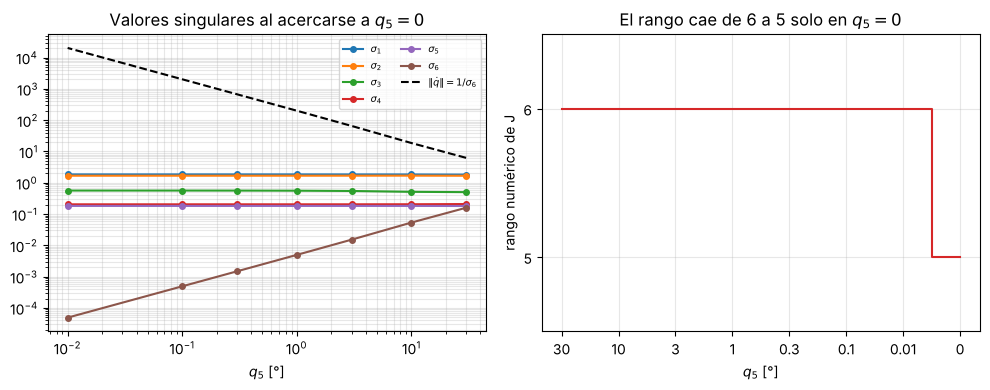

In [ ]:
Q5_DEG = [30, 10, 3, 1, 0.3, 0.1, 0.01, 0]
filas6 = []
print(f"{'q5 [°]':>7} {'σ6':>10} {'rango':>6} {'κ':>10} {'det J':>11} {'σ6/|sin q5|':>12} {'|q̇| = 1/σ6 [rad/s]':>20}")
for q5 in Q5_DEG:
    qe = QF.copy(); qe[4] = np.deg2rad(q5)
    r = jb.analisis_rango(jb.jacobiano(qe))
    filas6.append((q5, r))
    s6 = r["sigma"][-1]
    print(f"{q5:7.2f} {s6:10.2e} {r['rango']:6d} {r['kappa']:10.2e} {r['det']:11.2e} "
          f"{(s6 / abs(np.sin(qe[4])) if q5 else float('nan')):12.4f} {(1 / s6 if s6 > 1e-12 else float('inf')):20.1f}")

verificar("rango 6 para q5 ≠ 0 y rango 5 exactamente en q5 = 0",
          all(r["rango"] == 6 for q5, r in filas6[:-1]) and filas6[-1][1]["rango"] == 5)
cocientes = [r["sigma"][-1] / abs(np.sin(np.deg2rad(q5))) for q5, r in filas6[:-1] if q5 <= 0.3]
verificar(f"σ6 ∝ |sin q5| cerca de la singularidad (σ6/|sin q5| entre {min(cocientes):.4f} y {max(cocientes):.4f} para q5 ≤ 0.3°)",
          max(cocientes) / min(cocientes) < 1.01)

fig, axs = plt.subplots(1, 2, figsize=(10, 4))
q5_pos = np.array([q5 for q5, _ in filas6[:-1]])
S = np.array([r["sigma"] for _, r in filas6[:-1]])
for i in range(6):
    axs[0].loglog(q5_pos, S[:, i], "o-", ms=4, label=fr"$\sigma_{i+1}$")
axs[0].loglog(q5_pos, 1 / S[:, -1], "k--", label=r"$\|\dot q\| = 1/\sigma_6$")
axs[0].set_xlabel("$q_5$ [°]"); axs[0].set_title("Valores singulares al acercarse a $q_5 = 0$"); axs[0].legend(fontsize=7, ncol=2)
axs[0].grid(alpha=0.3, which="both")
xs = np.arange(len(filas6))
axs[1].step(xs, [r["rango"] for _, r in filas6], where="mid", color="tab:red")
axs[1].set_xticks(xs, [str(q5) for q5, _ in filas6]); axs[1].set_yticks([5, 6]); axs[1].set_ylim(4.5, 6.5)
axs[1].set_xlabel("$q_5$ [°]"); axs[1].set_ylabel("rango numérico de J"); axs[1].set_title("El rango cae de 6 a 5 solo en $q_5 = 0$")
axs[1].grid(alpha=0.3)
fig.tight_layout(); fig.savefig(FIG / "P6_experimento_singularidad.png", dpi=150); fig.savefig(FIG / "P6_experimento_singularidad.pdf")
plt.show()

### 6.7 Qué movilidad se pierde y qué NO significa

**Movimiento nulo.** En $q_5 = 0$ los ejes $z_3$ y $z_5$ coinciden, así que las juntas 4 y 6 giran alrededor del mismo
eje. El vector $v_6$ de la SVD es $\propto(0,0,0,1,0,-1)$: $\dot q_4 = -\dot q_6$ hace girar los dos motores en sentidos
opuestos y el TCP queda quieto.

**Dirección perdida.** La muñeca solo puede aportar velocidad angular en el plano de $z_3$ y $z_4$: se pierde la
rotación alrededor de $z_3\times z_4$. Con W como punto de referencia, la parte angular de $u_6$ es paralela a ese eje.

**Amplificación de velocidad, no torque infinito.** Cerca de la singularidad, producir un twist en la dirección $u_6$
exige $\lVert\dot q\rVert = 1/\sigma_6 \propto 1/|\sin q_5|$ (tabla de 6.6): velocidades articulares "inusualmente altas
y peligrosas" para una velocidad cartesiana finita (*Referencia visual W08, punto 4*). Pero la singularidad es **cinemática**: en
estática $\tau = J^T F$ (dualidad cinetoestática, Siciliano, sec. 3.8), y $J^T u_6 = \sigma_6 v_6 \to 0$. Una fuerza en
la dirección perdida **no pide torque**: la estructura la soporta. Los torques solo crecen si se **insiste** en seguir
una trayectoria **cartesiana** a través de la singularidad, porque $\ddot q = J^{-1}(\ddot x - \dot J\dot q)$ crece con
$1/\sigma_6$. La LSPB de este trabajo es articular y no invierte $J$.

In [ ]:
q_sing = QF.copy(); q_sing[4] = 0.0
r_s = jb.analisis_rango(jb.jacobiano(q_sing))
v6 = r_s["v_debil"] * np.sign(r_s["v_debil"][3])
print("v6 (movimiento articular nulo) =", np.round(v6, 4))
verificar("movimiento nulo en q5 = 0: v6 ∝ (0,0,0,1,0,-1), es decir q̇4 = −q̇6",
          np.allclose(np.abs(v6), np.array([0, 0, 0, 1, 0, 1]) / np.sqrt(2), atol=1e-9) and v6[5] < 0)
verificar(f"el TCP no se mueve con ese movimiento: |J v6| = {np.linalg.norm(jb.jacobiano(q_sing) @ v6):.1e}",
          np.linalg.norm(jb.jacobiano(q_sing) @ v6) < 1e-9)

T_s = m.marcos(q_sing)
eje_perdido = np.cross(T_s[3][:3, 2], T_s[4][:3, 2])
u6_W = jb.analisis_rango(jb.jacobiano(q_sing, "muneca"))["u_debil"]
cos_ang = abs(u6_W[3:] @ eje_perdido) / (np.linalg.norm(u6_W[3:]) * np.linalg.norm(eje_perdido))
verificar(f"dirección perdida (referencia W): parte angular de u6 paralela a z3 × z4 (|cos| = {cos_ang:.6f})", cos_ang > 1 - 1e-9)
verificar(f"J^T u6 = σ6 v6 ≈ 0: una fuerza en la dirección perdida no pide torque (|J^T u6| = {np.linalg.norm(jb.jacobiano(q_sing).T @ r_s['u_debil']):.1e})",
          np.linalg.norm(jb.jacobiano(q_sing).T @ r_s["u_debil"]) < 1e-9)
v45 = lspb.VMAX[4]
for q5, r in filas6:
    if 0 < q5 <= 1:
        print(f"q5 = {q5:5.2f}°: twist unitario en u6 pide |q̇| = {1 / r['sigma'][-1]:9.1f} rad/s  (vmax usado de q5: {v45:.2f} rad/s)")

v6 (movimiento articular nulo) = [-0.     -0.      0.      0.7071  0.     -0.7071]
✔ movimiento nulo en q5 = 0: v6 ∝ (0,0,0,1,0,-1), es decir q̇4 = −q̇6
✔ el TCP no se mueve con ese movimiento: |J v6| = 1.3e-15
✔ dirección perdida (referencia W): parte angular de u6 paralela a z3 × z4 (|cos| = 1.000000)
✔ J^T u6 = σ6 v6 ≈ 0: una fuerza en la dirección perdida no pide torque (|J^T u6| = 3.0e-16)
q5 =  1.00°: twist unitario en u6 pide |q̇| =     200.6 rad/s  (vmax usado de q5: 1.40 rad/s)
q5 =  0.30°: twist unitario en u6 pide |q̇| =     673.4 rad/s  (vmax usado de q5: 1.40 rad/s)
q5 =  0.10°: twist unitario en u6 pide |q̇| =    2024.3 rad/s  (vmax usado de q5: 1.40 rad/s)
q5 =  0.01°: twist unitario en u6 pide |q̇| =   20261.1 rad/s  (vmax usado de q5: 1.40 rad/s)


## 7. Dinámica reducida 1R sobre la trayectoria LSPB

La cinemática dice **cómo** se mueve el robot; la dinámica dice **cuánto esfuerzo** cuesta: $(q,\dot q,\ddot q)\to\tau$
(*W09-S02, diapositiva 2*). Para un robot de $n$ GDL la ecuación general es (*W09-S02, diapositiva 6*)

$$
\tau = M(q)\,\ddot q + C(q,\dot q)\,\dot q + g(q)
$$

con $M\ddot q$ el término **inercial**, $C\dot q$ los efectos de **Coriolis y centrífugos** (acoplamiento entre juntas) y
$g(q)$ la **gravedad**. La guía pide el **modelo reducido 1R estudiado en clase**, $\tau = J\ddot q + mg\ell_c\sin q$,
evaluado con la trayectoria LSPB, graficar $\tau(t)$ e interpretar las regiones de mayor esfuerzo y la diferencia
entre degradación cinemática (singularidad) y comportamiento dinámico (*Guía oficial Hito 2, sec. 3.4*). El handoff de
dinámica indica **no derivar los 6 GDL del IRB 120** sin datos inerciales del fabricante (*W09-S01, handoff, punto 0*).

Rúbrica E (15 %), nivel alto: usa el modelo 1R trabajado; documenta supuestos y parámetros; calcula $\tau$ a partir de
$q,\dot q,\ddot q$; separa e interpreta contribuciones; presenta $\tau(t)$ y lo relaciona con la trayectoria.

In [ ]:
import dinamica as dyn

### 7.1 Derivación por Euler-Lagrange (péndulo rígido 1R)

Eslabón rígido que gira en un plano vertical; $q$ se mide **desde la vertical hacia abajo**, $m$ es la masa, $\ell_c$ la
distancia de la junta al centro de masa e $I_c$ la inercia respecto al centro de masa (*W09-S02, diapositivas 3 a 5*):

1. **Inercia en la junta** (Steiner): $J = I_c + m\ell_c^2$.
2. **Energías:** $T = \tfrac12 J\dot q^2$, $\quad V = mg\ell_c(1-\cos q)$.
3. **Lagrangiano:** $L = T - V = \tfrac12 J\dot q^2 - mg\ell_c(1-\cos q)$.
4. **Derivadas:** $\dfrac{\partial L}{\partial\dot q} = J\dot q \Rightarrow \dfrac{d}{dt}\dfrac{\partial L}{\partial\dot q} = J\ddot q$, $\quad \dfrac{\partial L}{\partial q} = -mg\ell_c\sin q$.
5. **Euler-Lagrange:** $\dfrac{d}{dt}\dfrac{\partial L}{\partial\dot q} - \dfrac{\partial L}{\partial q} = \tau$:

$$
\boxed{\tau = \underbrace{J\ddot q}_{\tau_I\ \text{inercial}} + \underbrace{mg\ell_c\sin q}_{\tau_g\ \text{gravedad}}}
$$

En 1R no hay término de Coriolis ($C = 0$): es el único caso sin acoplamiento entre juntas (*W09-S02, diapositiva 6;
solucionario W09-S02*). Código: `dinamica.py`, función `tau_1r`.

### 7.2 Validación con los casos de clase

Antes de usarlo en el robot, el código reproduce los resultados de clase:

- **Estática** (*W09-S02, diapositiva 5*): con $\dot q = \ddot q = 0$, $\tau(0) = 0$ y $\tau(\pi/2) = mg\ell_c$.
- **Hoja de trabajo W09-S02, ejercicio 3** ($m = 2$ kg, $\ell_c = 0.4$ m): $\tau = 7.848\sin q$; en $\pi/6$ da 3.924 N·m.
- **Ejercicio 4** ($J = 0.4$ kg·m², $\ddot q = 3$ rad/s²): $\tau_I = 1.2$ N·m.
- **Tabla de la diapositiva 8** (1R ilustrativo $J = 0.25$, $m = 1$, $\ell_c = 0.5$; LSPB de clase $0\to2$ rad,
  $t_f = 3$ s, $\ddot q_c = 1$): 0.86, 4.13 y 4.43 N·m en $t = 0.5$, 1.5 y 2.5 s.

In [ ]:
verificar("estática: τ(0) = 0 y τ(π/2) = m g lc", np.isclose(dyn.tau_1r(0.0, 0.0)[2], 0.0)
          and np.isclose(dyn.tau_1r(np.pi / 2, 0.0)[2], dyn.M_KG * dyn.G * dyn.LC_M))
verificar("W09-S02 ej. 3: τ(π/6) = 3.924 N·m con m = 2 kg, lc = 0.4 m",
          np.isclose(dyn.tau_1r(np.pi / 6, 0.0, m=2.0, lc=0.4)[2], 3.924, atol=5e-4))
verificar("W09-S02 ej. 4: τ_I = 1.2 N·m con J = 0.4 kg·m², q̈ = 3 rad/s²", np.isclose(dyn.tau_1r(0.0, 3.0, J=0.4)[0], 1.2))

def lspb_clase(tk, qi=0.0, qf=2.0, tf=3.0, a=1.0, tc=1.0):
    # perfil de la clase W09-S01/S02 (qi = 0 -> qf = 2 rad, tf = 3 s, q̈c = 1 rad/s², tc = 1 s)
    if tk <= tc:
        return qi + 0.5 * a * tk**2, a
    if tk <= tf - tc:
        return qi + a * tc * (tk - tc / 2), 0.0
    return qf - 0.5 * a * (tf - tk)**2, -a

tabla_clase = {0.5: 0.86, 1.5: 4.13, 2.5: 4.43}
for tk, esperado in tabla_clase.items():
    qk, qddk = lspb_clase(tk)
    tau_k = dyn.tau_1r(qk, qddk, J=0.25, m=1.0, lc=0.5)[2]
    verificar(f"W09-S02 diap. 8: t = {tk} s -> τ = {tau_k:.2f} N·m (clase: {esperado})", round(tau_k, 2) == esperado)

✔ estática: τ(0) = 0 y τ(π/2) = m g lc
✔ W09-S02 ej. 3: τ(π/6) = 3.924 N·m con m = 2 kg, lc = 0.4 m
✔ W09-S02 ej. 4: τ_I = 1.2 N·m con J = 0.4 kg·m², q̈ = 3 rad/s²
✔ W09-S02 diap. 8: t = 0.5 s -> τ = 0.86 N·m (clase: 0.86)
✔ W09-S02 diap. 8: t = 1.5 s -> τ = 4.13 N·m (clase: 4.13)
✔ W09-S02 diap. 8: t = 2.5 s -> τ = 4.43 N·m (clase: 4.43)


### 7.3 Aplicación al IRB 120: qué junta, qué parámetros y qué supuestos

**Junta elegida: la 3 (codo), moviendo el antebrazo** (codo → centro de muñeca W). Es la que tiene la **gravedad más
cambiante** en esta trayectoria: en $q_i$ el antebrazo está casi horizontal (brazo de palanca máximo) y durante el
movimiento baja hasta unos 46° de la vertical, **cruzando la horizontal**. El hombro (junta 2) apenas se mueve 9.6°
y la muñeca tiene palancas pequeñas.

**Ángulo del 1R.** Los ejes 2 y 3 son paralelos y horizontales, así que la orientación del antebrazo respecto a la
vertical es la suma $q_2 + q_3$ más una constante geométrica. Medido desde la vertical hacia abajo, positivo en el
sentido de $q_3$ (en $q = 0$ el antebrazo apunta a W, 13.05° sobre la horizontal):

$$
\theta = q_2 + q_3 - \delta - \frac{\pi}{2},\qquad \dot\theta = \dot q_2 + \dot q_3,\qquad \ddot\theta = \ddot q_2 + \ddot q_3
$$

| Parámetro | Valor | Procedencia |
|---|---|---|
| Longitud del antebrazo $L$ | 0.310 m | $\sqrt{a_3^2 + d_4^2}$, tabla DH (Bahani et al., 2023) = $L_3$ de Pieper |
| Centro de masa $\ell_c$ | $L/2$ = 0.155 m | **Supuesto:** barra uniforme |
| Masa $m$ | 1 kg | **Ilustrativa**, la del modelo 1R de clase (*W09-S02, código torque_python*). ABB no publica masas por eslabón |
| $I_c$ | $mL^2/12$ | Barra uniforme respecto a su centro |
| $J$ | $I_c + m\ell_c^2 = mL^2/3$ = 0.0320 kg·m² | Steiner (*W09-S02, diapositiva 4*) |
| $g$ | 9.81 m/s² | |

**Supuestos declarados.** (1) Eje del codo fijo: se desprecia que el hombro lo traslada y el acoplamiento de
Coriolis/centrífugo con las otras juntas (en el robot real $C \ne 0$). (2) Solo el antebrazo: la muñeca, la
herramienta y la carga no se incluyen. (3) Sin fricción ni inercia del rotor. (4) **$\tau$ es lineal en $m$** (también
$J \propto m$): para otra masa basta multiplicar; las formas de las curvas y las conclusiones no cambian.

**Validación del 1R con la geometría 3D.** El término de gravedad del 1R debe ser igual al momento del peso del
antebrazo respecto al eje del codo $z_2$, calculado con la FK completa: $\tau_g = z_2\cdot\big((p_c - o_2)\times(0,0,mg)\big)$.

In [ ]:
print(f"L = {dyn.L_M:.4f} m,  lc = {dyn.LC_M:.4f} m,  m = {dyn.M_KG} kg,  J = {dyn.J_KGM2:.5f} kg·m²")
t7, q7, qd7, qdd7 = TR.muestrear(1201)
th = dyn.angulo_antebrazo(q7)
thd = qd7[:, 1] + qd7[:, 2]
thdd = qdd7[:, 1] + qdd7[:, 2]
tau_I, tau_g, tau = dyn.tau_1r(th, thdd)
err_g = max(abs(dyn.tau_gravedad_exacta(qk) - tg) for qk, tg in zip(q7, tau_g))
verificar(f"τ_g del 1R = momento del peso respecto al eje del codo con la FK 3D (dif. máx {err_g:.1e} N·m)", err_g < 1e-9)
print(f"θ: {np.rad2deg(th[0]):.2f}° en q_i -> {np.rad2deg(th[-1]):.2f}° en q_f   (θ = ±90°: antebrazo horizontal)")

L = 0.3100 m,  lc = 0.1550 m,  m = 1.0 kg,  J = 0.03203 kg·m²
✔ τ_g del 1R = momento del peso respecto al eje del codo con la FK 3D (dif. máx 6.7e-16 N·m)
θ: -103.05° en q_i -> -46.29° en q_f   (θ = ±90°: antebrazo horizontal)


### 7.4 $\tau(t)$ sobre la LSPB y sus contribuciones

Se inyectan $q(t),\dot q(t),\ddot q(t)$ de la LSPB de la sección 5 (*W09-S02, diapositiva 7*). Las gráficas están
alineadas en el tiempo con las fases de la LSPB (*matriz diagnóstica W10-S01*).

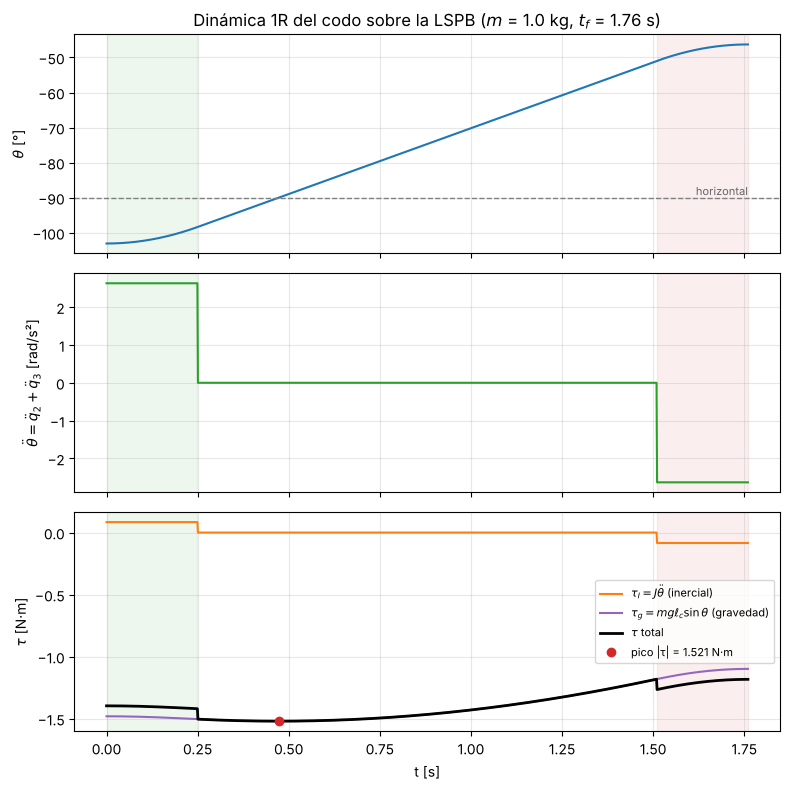

fase              t [s]    θ [°]  θ̈ [rad/s²]  τ_I [N·m]  τ_g [N·m]   τ [N·m]
aceleración       0.125  -101.88        2.630     0.0842    -1.4880   -1.4038
vel. constante    0.880   -74.67        0.000     0.0000    -1.4665   -1.4665
desaceleración    1.635   -47.47       -2.630    -0.0842    -1.1205   -1.2047

pico |τ| = 1.5206 N·m en t = 0.472 s (vel. constante), θ = -89.99°
|τ_I| máx = 0.0842 N·m  vs  |τ_g| máx = 1.5206 N·m
✔ en velocidad constante θ̈ = 0, pero τ ≠ 0 (la gravedad sigue actuando)
✔ τ_I es un reflejo de θ̈: escalones en t_c y t_f − t_c


In [ ]:
fig, axs = plt.subplots(3, 1, figsize=(8, 8), sharex=True)
axs[0].plot(t7, np.rad2deg(th), color="tab:blue")
axs[0].axhline(-90, color="0.5", linestyle="--", linewidth=1)
axs[0].text(t7[-1], -90, " horizontal", va="bottom", ha="right", fontsize=8, color="0.4")
axs[0].set_ylabel(r"$\theta$ [°]")
axs[1].plot(t7, thdd, color="tab:green"); axs[1].set_ylabel(r"$\ddot\theta = \ddot q_2 + \ddot q_3$ [rad/s²]")
axs[2].plot(t7, tau_I, label=r"$\tau_I = J\ddot\theta$ (inercial)", color="tab:orange")
axs[2].plot(t7, tau_g, label=r"$\tau_g = mg\ell_c\sin\theta$ (gravedad)", color="tab:purple")
axs[2].plot(t7, tau, label=r"$\tau$ total", color="k", linewidth=2)
k_pico = np.argmax(np.abs(tau))
axs[2].plot(t7[k_pico], tau[k_pico], "o", color="tab:red", label=f"pico |τ| = {abs(tau[k_pico]):.3f} N·m")
axs[2].set_ylabel(r"$\tau$ [N·m]"); axs[2].legend(fontsize=8, loc="center right")
for ax in axs:
    ax.axvspan(0, TR.tc, color="tab:green", alpha=0.08); ax.axvspan(TR.tf - TR.tc, TR.tf, color="tab:red", alpha=0.08)
    ax.grid(alpha=0.3)
axs[0].set_title(f"Dinámica 1R del codo sobre la LSPB ($m$ = {dyn.M_KG} kg, $t_f$ = {TR.tf:.2f} s)")
axs[2].set_xlabel("t [s]")
fig.tight_layout(); fig.savefig(FIG / "P7_torque_1R.png", dpi=150); fig.savefig(FIG / "P7_torque_1R.pdf")
plt.show()

print(f"{'fase':<16} {'t [s]':>6} {'θ [°]':>8} {'θ̈ [rad/s²]':>12} {'τ_I [N·m]':>10} {'τ_g [N·m]':>10} {'τ [N·m]':>9}")
for fase, tk in (("aceleración", TR.tc / 2), ("vel. constante", TR.tf / 2), ("desaceleración", TR.tf - TR.tc / 2)):
    i = np.argmin(np.abs(t7 - tk))
    print(f"{fase:<16} {t7[i]:6.3f} {np.rad2deg(th[i]):8.2f} {thdd[i]:12.3f} {tau_I[i]:10.4f} {tau_g[i]:10.4f} {tau[i]:9.4f}")
print(f"\npico |τ| = {abs(tau[k_pico]):.4f} N·m en t = {t7[k_pico]:.3f} s ({TR.fase(t7[k_pico])}), θ = {np.rad2deg(th[k_pico]):.2f}°")
print(f"|τ_I| máx = {np.abs(tau_I).max():.4f} N·m  vs  |τ_g| máx = {np.abs(tau_g).max():.4f} N·m")
crucero = (t7 > TR.tc) & (t7 < TR.tf - TR.tc)
verificar("en velocidad constante θ̈ = 0, pero τ ≠ 0 (la gravedad sigue actuando)",
          np.allclose(tau_I[crucero], 0) and np.abs(tau[crucero]).min() > 0.5)
verificar("τ_I es un reflejo de θ̈: escalones en t_c y t_f − t_c", np.allclose(tau_I, dyn.J_KGM2 * thdd))

**Lectura (relación con la trayectoria).**

- **$\tau_I$ copia el perfil de $\ddot\theta$**: escalón positivo en la aceleración, cero en velocidad constante y escalón
  negativo en la desaceleración (*W09-S02, código torque_python, interpretación obligatoria*).
- **$\tau_g$ evoluciona suave, como $\sin\theta$**: depende solo de la postura. Es negativo porque el motor sostiene el
  antebrazo para que no caiga hacia adelante.
- **El pico de $|\tau|$ no está en la máxima aceleración**: ocurre en la fase de velocidad constante, cuando el antebrazo
  pasa por la **horizontal** ($\theta = -90°$, brazo de palanca máximo). Ahí $\ddot\theta = 0$ y todo el esfuerzo es
  gravitacional (*W09-S02, diapositiva 8: "aceleración nula no significa torque cero"*).
- Con esta trayectoria lenta ($v_{\max}$ al 25 %), **la gravedad domina**: $|\tau_I|$ es pocos % de $|\tau_g|$. La razón
  entre las dos no depende de $m$, porque las dos son proporcionales a $m$.
- En la aceleración, $\tau_I > 0$ **se resta** de $\tau_g < 0$; en la desaceleración **se suma**. La gravedad puede
  sumarse o restarse según la postura (*W09-S02, torque_python*).

### 7.5 Validación energética

Independiente de la fórmula: la potencia del actuador es $\tau\dot\theta$, y como la LSPB empieza y termina en reposo
($\Delta T = 0$), el trabajo total debe ser el cambio de energía potencial:
$\int_0^{t_f}\tau\,\dot\theta\,dt = \Delta V = mg\ell_c(\cos\theta_i - \cos\theta_f)$.

In [ ]:
t_fino, q_fino, qd_fino, qdd_fino = TR.muestrear(40001)
th_f = dyn.angulo_antebrazo(q_fino); thd_f = qd_fino[:, 1] + qd_fino[:, 2]; thdd_f = qdd_fino[:, 1] + qdd_fino[:, 2]
pot = dyn.tau_1r(th_f, thdd_f)[2] * thd_f
W = np.sum((pot[1:] + pot[:-1]) / 2 * np.diff(t_fino))
dV = dyn.M_KG * dyn.G * dyn.LC_M * (np.cos(th_f[0]) - np.cos(th_f[-1]))
verificar(f"trabajo del motor ∫τ θ̇ dt = {W:.6f} J = ΔV = {dV:.6f} J", abs(W - dV) < 1e-5)

✔ trabajo del motor ∫τ θ̇ dt = -1.393990 J = ΔV = -1.393990 J


### 7.6 Misma ruta, distinto tiempo

La misma ruta en menos tiempo exige más aceleración y por eso más torque inercial (*W09-S02, diapositiva 2 y
ejercicio 6*). Si la trayectoria se recorre $k$ veces más rápido ($t_f/k$), la postura en cada punto de la ruta es la
misma ($\tau_g$ igual) pero $\ddot\theta$ se multiplica por $k^2$. Con $k = 4$ (equivalente a usar el 100 % de la
velocidad del datasheet en lugar del 25 %):

In [ ]:
for k in (1, 2, 4):
    tI_k, tg_k, t_k = dyn.tau_1r(th, thdd * k**2)
    print(f"k = {k}: t_f = {TR.tf / k:5.3f} s   |τ_I| máx = {np.abs(tI_k).max():.3f} N·m   |τ| máx = {np.abs(t_k).max():.3f} N·m")
verificar("τ_I escala con k² al acortar el tiempo", np.isclose(np.abs(dyn.tau_1r(th, thdd * 16)[0]).max(), 16 * np.abs(tau_I).max()))

k = 1: t_f = 1.760 s   |τ_I| máx = 0.084 N·m   |τ| máx = 1.521 N·m
k = 2: t_f = 0.880 s   |τ_I| máx = 0.337 N·m   |τ| máx = 1.521 N·m
k = 4: t_f = 0.440 s   |τ_I| máx = 1.348 N·m   |τ| máx = 2.529 N·m
✔ τ_I escala con k² al acortar el tiempo


Con $k = 4$ el término inercial pasa a ser del mismo orden que la gravedad: el pico de esfuerzo se desplaza hacia
las fases de aceleración y desaceleración. Por eso el tiempo de la trayectoria es una decisión de diseño dinámica.

### 7.7 Singularidad cinemática ≠ torque alto

La singularidad se define **solo** por la pérdida de rango de $J(q)$ (movilidad); el torque depende de inercias,
velocidades y gravedad (*W09-S02, diapositiva 9; solucionario W09-S02, ejercicio 7*). En esta trayectoria:

In [ ]:
rango_t7 = np.array([jb.analisis_rango(jb.jacobiano(qk))["rango"] for qk in q7[:5]])
print(f"t = 0: rango J = {rango_t7[0]} (muñeca singular, q5 = 0)  y  τ = {tau[0]:.4f} N·m (solo gravedad, finito)")
print(f"pico |τ| en t = {t7[k_pico]:.3f} s: rango J = {jb.analisis_rango(jb.jacobiano(q7[k_pico]))['rango']} (postura regular)")
verificar("el pico de torque ocurre en una postura regular (rango 6), no en la singular",
          jb.analisis_rango(jb.jacobiano(q7[k_pico]))["rango"] == 6 and rango_t7[0] == 5)

t = 0: rango J = 5 (muñeca singular, q5 = 0)  y  τ = -1.3971 N·m (solo gravedad, finito)
pico |τ| en t = 0.472 s: rango J = 6 (postura regular)
✔ el pico de torque ocurre en una postura regular (rango 6), no en la singular


El robot **arranca en una singularidad de muñeca** con un torque de codo finito y moderado, y su mayor esfuerzo
aparece después, en una postura **regular**, por la gravedad. Lo que una singularidad amplifica son las **velocidades
articulares** necesarias para ciertos movimientos cartesianos (sección 6.6), no el torque.

## Resumen

- `m.DH`, `m.TCP_M`, `m.LIMITES_RAD`, `m.fk(q)`: modelo del robot y cinemática directa al TCP.
- `m.Q_I`: configuración inicial.
- `T_D`: la pose objetivo (`T_D["T_d"]`).
- `RAMAS[nombre]`: las 8 ramas de Pieper de la pose, con su verificación FK y su admisibilidad.
- `Q_F[nombre]`: configuración final elegida y justificada.
- `TRAY[nombre]`: trayectoria LSPB sincronizada de $q_i$ a $q_f$; `TRAY[nombre].muestrear()` da $t, q, \dot q, \ddot q$.

- `jb.jacobiano(q)`, `jb.analisis_rango(J)`: Jacobiano geométrico y análisis de rango por SVD (sección 6).
- `dyn.tau_1r(θ, θ̈)`: dinámica 1R del codo sobre la LSPB, separada en inercial y gravedad (sección 7).

**Siguiente paso:** gráficas finales, discusión y conclusiones (secciones 8 y 9 del esqueleto oficial) e informe IEEE.

In [ ]:
print(f"{sum(ok for _, ok in VERIFICACIONES)}/{len(VERIFICACIONES)} verificaciones aprobadas")

51/51 verificaciones aprobadas
